**Тут буду проводить свой EDA под датасет**

In [152]:
import pandas as pd
import numpy as np
import seaborn as sns
from matplotlib import pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf

In [153]:
DATA_PATH = "./.data/hu_intraday_vwap_15min_2023_2025.csv"
df = pd.read_csv(DATA_PATH)

In [154]:
df.columns

Index(['timestamp', 'QH WAP', 'demand_forecast_mwh', 'wind_forecast_mwh',
       'solar_forecast_mwh', 'nuclear_forecast_mwh', 'temperature_forecast_c',
       'net_exchange_forecast_mwh'],
      dtype='str')

In [155]:
df = df.rename(columns={'QH WAP': 'QH_WAP'})

In [156]:
df.columns

Index(['timestamp', 'QH_WAP', 'demand_forecast_mwh', 'wind_forecast_mwh',
       'solar_forecast_mwh', 'nuclear_forecast_mwh', 'temperature_forecast_c',
       'net_exchange_forecast_mwh'],
      dtype='str')

Проведем изначально базовый EDA

-посмотрим размерности

-как представлены данные

-посмотрим также сводку

In [157]:
df.head()

,timestamp,QH_WAP,demand_forecast_mwh,wind_forecast_mwh,solar_forecast_mwh,nuclear_forecast_mwh,temperature_forecast_c,net_exchange_forecast_mwh
0,2022-12-31 23:00:00+00:00,22.89,3978.2,125.6,0.0,1900.0,5.77,-983.2
1,2022-12-31 23:15:00+00:00,6.54,3994.7,125.1,0.0,1900.0,5.55,-983.2
2,2022-12-31 23:30:00+00:00,4.44,3988.3,126.8,0.0,1900.0,5.36,-983.2
3,2022-12-31 23:45:00+00:00,1.13,3956.0,126.7,0.0,1900.0,5.24,-983.2
4,2023-01-01 00:00:00+00:00,5.30,3936.8,127.4,0.0,1900.0,5.18,-900.0


In [158]:
df.tail()

,timestamp,QH_WAP,demand_forecast_mwh,wind_forecast_mwh,solar_forecast_mwh,nuclear_forecast_mwh,temperature_forecast_c,net_exchange_forecast_mwh
105211,2025-12-31 21:45:00+00:00,86.81,5240.0,142.5,0.0,1920.0,-2.26,-1974.3
105212,2025-12-31 22:00:00+00:00,93.70,5259.9,143.7,0.0,1920.0,-2.22,-1925.5
105213,2025-12-31 22:15:00+00:00,87.73,5243.8,145.3,0.0,1920.0,-2.16,-1925.5
105214,2025-12-31 22:30:00+00:00,71.95,5227.5,145.5,0.0,1920.0,-2.08,-1925.5
105215,2025-12-31 22:45:00+00:00,NaN,5191.9,147.3,0.0,1920.0,-1.99,-1925.5


In [159]:
df.shape

(105216, 8)

In [160]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 105216 entries, 0 to 105215
Data columns (total 8 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   timestamp                  105216 non-null  str    
 1   QH_WAP                     105122 non-null  float64
 2   demand_forecast_mwh        105216 non-null  float64
 3   wind_forecast_mwh          105216 non-null  float64
 4   solar_forecast_mwh         105216 non-null  float64
 5   nuclear_forecast_mwh       105216 non-null  float64
 6   temperature_forecast_c     105216 non-null  float64
 7   net_exchange_forecast_mwh  105216 non-null  float64
dtypes: float64(7), str(1)
memory usage: 6.4 MB


Выводы:
1. Сразу можно заметить что есть пропуски в целевой переменной
2. timestamp в формате str - надо будет заменить на другой тип данных, так как невозможно будет обработать

In [161]:
df.isnull().sum()

timestamp                     0
QH_WAP                       94
demand_forecast_mwh           0
wind_forecast_mwh             0
solar_forecast_mwh            0
nuclear_forecast_mwh          0
temperature_forecast_c        0
net_exchange_forecast_mwh     0
dtype: int64

In [162]:
df.describe()

,QH_WAP,demand_forecast_mwh,wind_forecast_mwh,solar_forecast_mwh,nuclear_forecast_mwh,temperature_forecast_c,net_exchange_forecast_mwh
count,105122.000000,105216.000000,105216.000000,105216.000000,105216.000000,105216.000000,105216.000000
mean,107.527928,4892.300391,67.763118,614.153365,1731.612720,12.529461,-1130.725236
std,82.040454,827.044427,62.953986,905.099074,236.179614,9.209502,1227.760098
min,-561.850000,2332.800000,0.400000,0.000000,956.000000,-7.350000,-5365.300000
25%,69.430000,4262.800000,17.500000,0.000000,1428.000000,4.860000,-1988.325000
50%,99.440000,4827.600000,48.100000,16.150000,1900.000000,12.130000,-1300.000000
75%,135.340000,5453.200000,99.100000,1046.500000,1900.000000,19.750000,-436.250000
max,6326.670000,7376.400000,300.400000,4207.600000,2039.000000,36.010000,3819.900000


Выводы:

* Пропуски в целевой переменной (94 пропуска)

* 25-й квартиль 0 у признака solar_forecast_mwh - посмотрим на данный и на время - может это ночной период когда нет солнца

* У признака nuclear_forecast_mwh	50% и 75% квартили одинаковые значения - между ними стоят одинаковые значения 1900



### Работа с timestamp 

Предлагаю перевести его в другой тип данных, чтобы было легче ранжировать данные

In [163]:
df['timestamp'] = pd.to_datetime(df['timestamp'])
df['timestamp'] = df['timestamp'].dt.tz_convert('Europe/Budapest')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 105216 entries, 0 to 105215
Data columns (total 8 columns):
 #   Column                     Non-Null Count   Dtype                          
---  ------                     --------------   -----                          
 0   timestamp                  105216 non-null  datetime64[us, Europe/Budapest]
 1   QH_WAP                     105122 non-null  float64                        
 2   demand_forecast_mwh        105216 non-null  float64                        
 3   wind_forecast_mwh          105216 non-null  float64                        
 4   solar_forecast_mwh         105216 non-null  float64                        
 5   nuclear_forecast_mwh       105216 non-null  float64                        
 6   temperature_forecast_c     105216 non-null  float64                        
 7   net_exchange_forecast_mwh  105216 non-null  float64                        
dtypes: datetime64[us, Europe/Budapest](1), float64(7)
memory usage: 6.4 MB


In [164]:
df['timestamp'].head()

0   2023-01-01 00:00:00+01:00
1   2023-01-01 00:15:00+01:00
2   2023-01-01 00:30:00+01:00
3   2023-01-01 00:45:00+01:00
4   2023-01-01 01:00:00+01:00
Name: timestamp, dtype: datetime64[us, Europe/Budapest]

### Анализ признаков (Однофакторный анализ)

In [165]:
X = df.drop(columns=['timestamp','QH_WAP'])
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 105216 entries, 0 to 105215
Data columns (total 6 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   demand_forecast_mwh        105216 non-null  float64
 1   wind_forecast_mwh          105216 non-null  float64
 2   solar_forecast_mwh         105216 non-null  float64
 3   nuclear_forecast_mwh       105216 non-null  float64
 4   temperature_forecast_c     105216 non-null  float64
 5   net_exchange_forecast_mwh  105216 non-null  float64
dtypes: float64(6)
memory usage: 4.8 MB


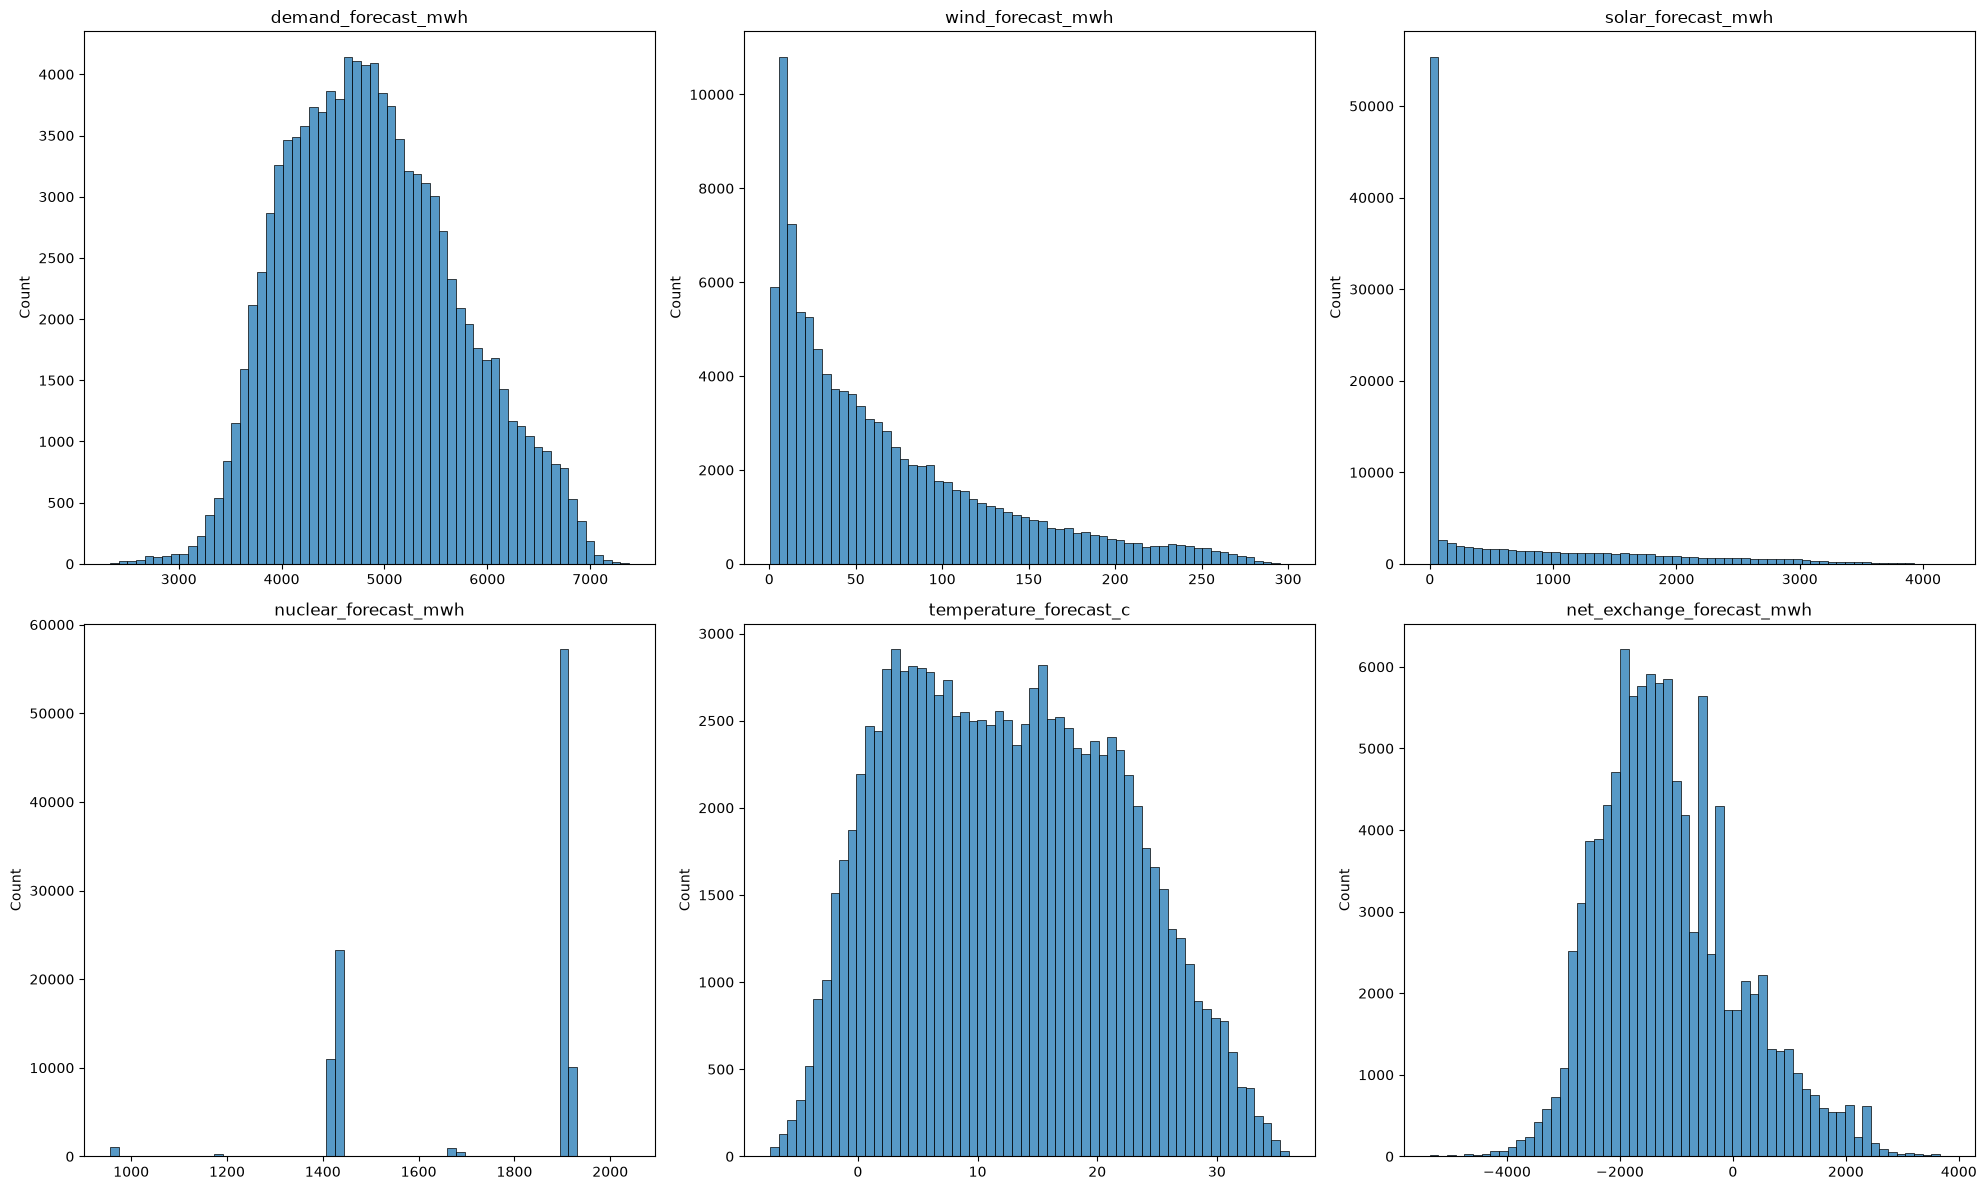

In [166]:
cols = X.columns

fig, axes = plt.subplots(2, 3, figsize=(20, 12))
for ax, col in zip(axes.flat, X.columns):
    sns.histplot(X[col], bins=60, ax=ax)
    ax.set_title(col)
    ax.set_xlabel('')
plt.tight_layout()
plt.show()

Выводы:
* Предпологаю что нулевые значения в wind_forecast_mwh связаны с географическим положением (если это венгрия то там "не ветренно совсем" такой климат)
для венгрии это не основной источник

* solar_forecast_mwh нули также связаны с географическим положением и сезонностью (солнечные часы меняються в течении года)

* nuclear_forecast_mwh разбиты на конкретные блоки 1400 1700 и 1900 - веротяно из - за различных режимов работы АЭС




*Посмотрим на выбросы*

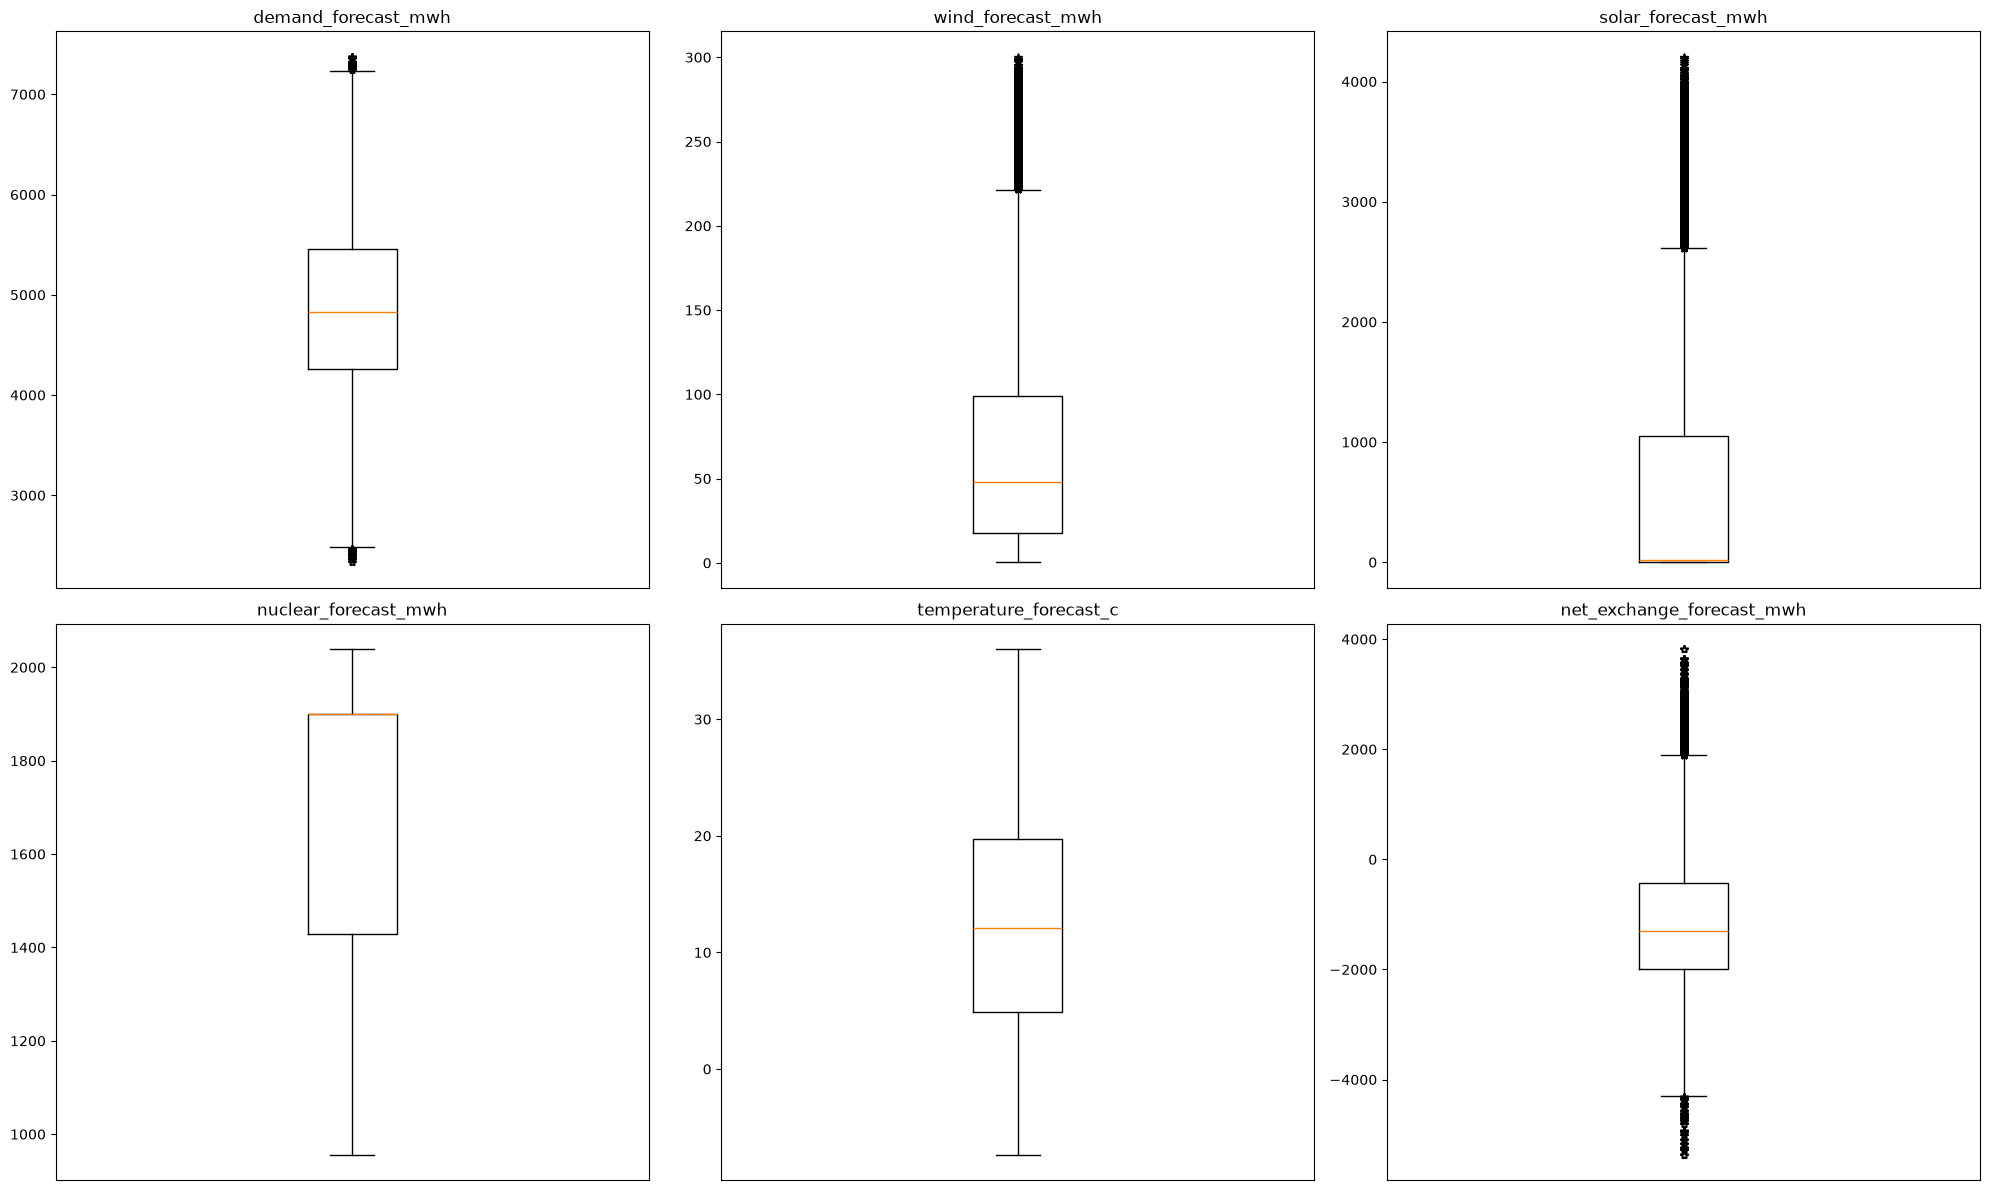

In [167]:
fig, axes = plt.subplots(2, 3, figsize=(20, 12))
for ax, col in zip(axes.flat, X.columns):
    ax.boxplot(X[col].dropna(), sym='*')
    ax.set_title(col)
    ax.set_xticks([])
plt.tight_layout()
plt.show()

Можно сделать аналогичные выводы:
* на wind_forecast четко показывает что ветренных дней мало - однако они бывают (аналогично с солнечными днями)

*nuclear_forecast ровный, медиана находиться на 1900 и это значит что АЭС работает на полную

Возможные выбросы присутствуют у wind_forecast, solar_forecast, net_exchange_forecast


In [168]:
for cols in X.columns:
    Q1 = df[cols].quantile(0.25)
    Q3 = df[cols].quantile(0.75)
    IQR = Q3 - Q1

    lower_us = Q1 - 1.5 * IQR
    higer_us = Q3 + 1.5 * IQR

    beyond = df[(df[cols] < lower_us) | (df[cols] > higer_us)]
    print(f'Количество аномальных значений {cols}: {len(beyond)}')
    print(f'Их процент: {len(beyond) / len(df) * 100:.2f}%')
    print()

Количество аномальных значений demand_forecast_mwh: 47
Их процент: 0.04%

Количество аномальных значений wind_forecast_mwh: 3719
Их процент: 3.53%

Количество аномальных значений solar_forecast_mwh: 5510
Их процент: 5.24%

Количество аномальных значений nuclear_forecast_mwh: 0
Их процент: 0.00%

Количество аномальных значений temperature_forecast_c: 0
Их процент: 0.00%

Количество аномальных значений net_exchange_forecast_mwh: 2404
Их процент: 2.28%



### demand_forecast_mwh

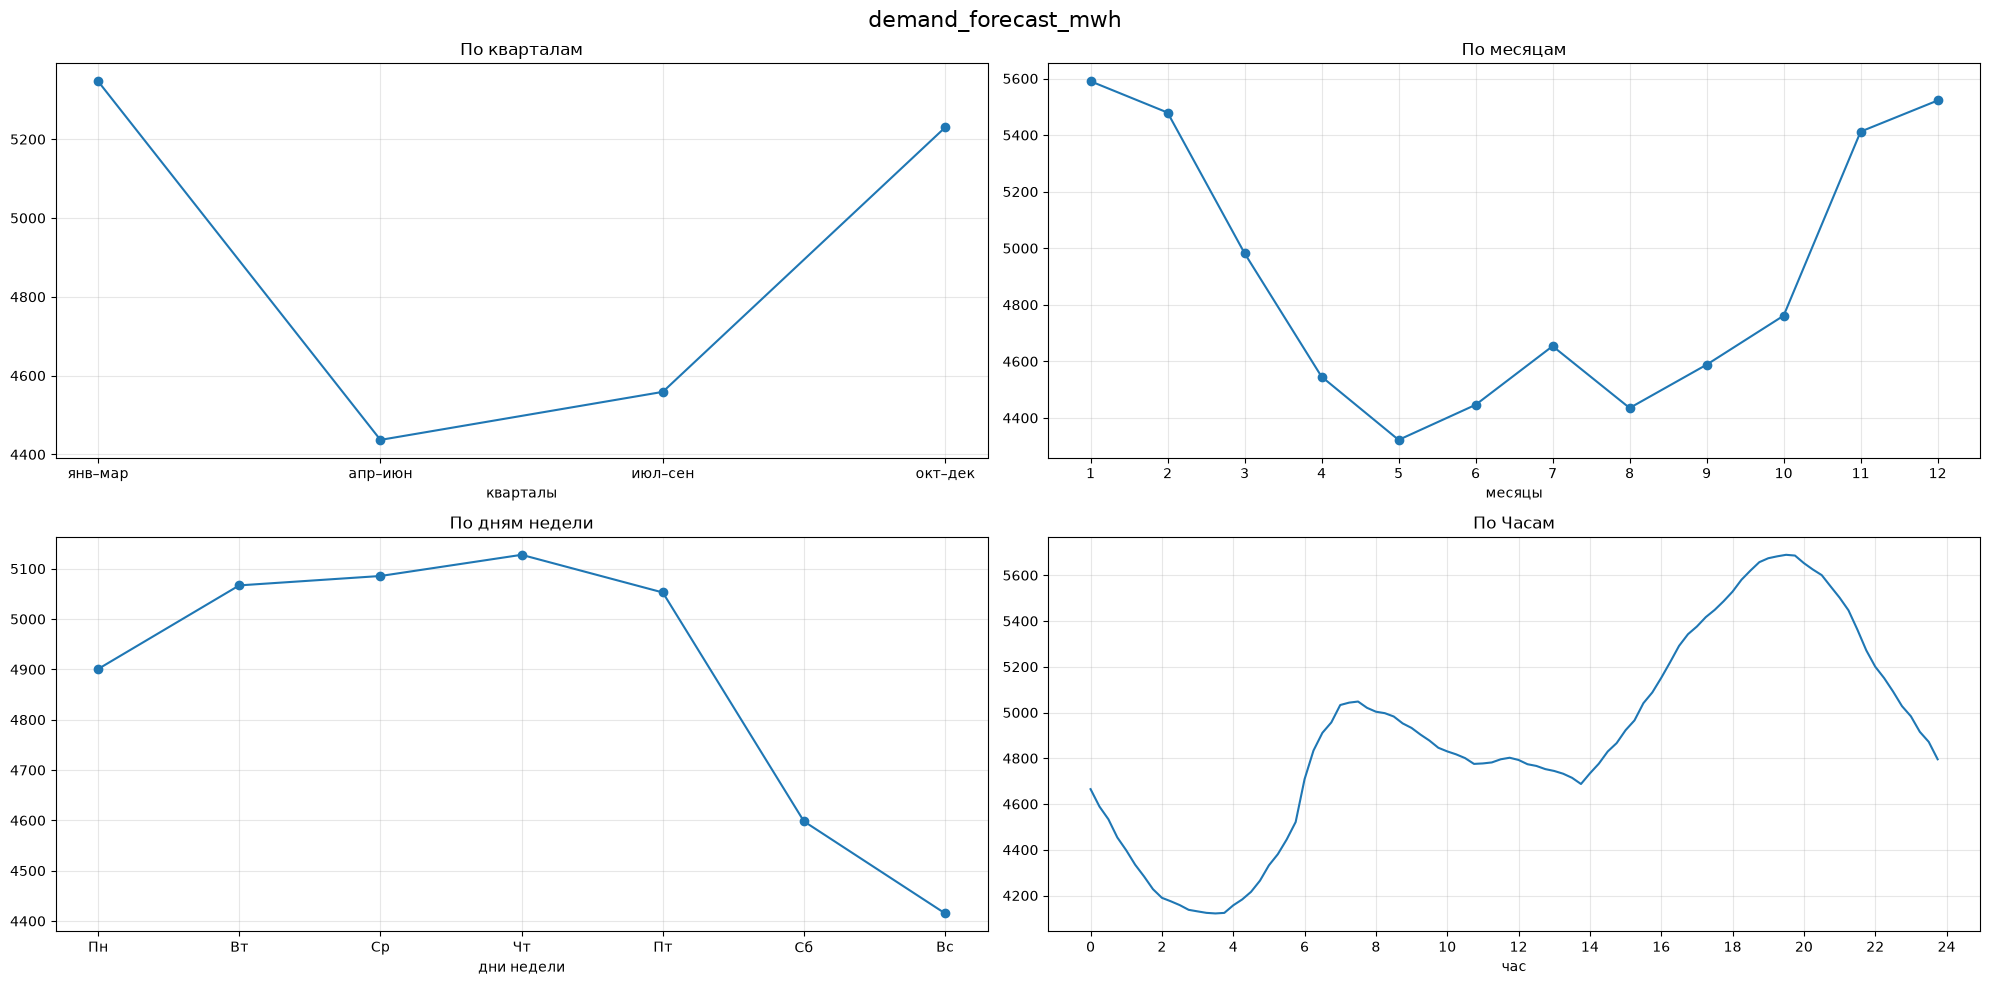

In [169]:

col = X.columns[0]
fig, axes = plt.subplots(2, 2, figsize=(20, 10))
quarter = df['timestamp'].dt.quarter
X[col].groupby(quarter).mean().plot(ax=axes[0, 0], marker='o')
axes[0, 0].set_title('По кварталам')
axes[0, 0].set_xticks([1, 2, 3, 4])
axes[0, 0].set_xlabel('кварталы')
axes[0, 0].set_xticklabels(['янв–мар', 'апр–июн', 'июл–сен', 'окт–дек'])

months = df['timestamp'].dt.month
X[col].groupby(months).mean().plot(ax=axes[0, 1], marker='o')
axes[0, 1].set_title('По месяцам')
axes[0, 1].set_xticks(range(1, 13))
axes[0, 1].set_xlabel('месяцы')

dow = df['timestamp'].dt.day_of_week
X[col].groupby(dow).mean().plot(ax=axes[1, 0], marker='o')
axes[1, 0].set_title('По дням недели')
axes[1, 0].set_xticks(range(7))
axes[1, 0].set_xticklabels(['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс'])
axes[1, 0].set_xlabel('дни недели')

time_of_day = df['timestamp'].dt.hour + df['timestamp'].dt.minute / 60
X[col].groupby(time_of_day).mean().plot(ax=axes[1, 1])
axes[1, 1].set_title('По Часам')
axes[1, 1].set_xticks(range(0, 25, 2))
axes[1, 1].set_xlabel('час')

for ax in axes.flat:
    ax.grid(alpha=0.3)

fig.suptitle(col, fontsize=16)
plt.tight_layout()
plt.show()

Выводы:

*  Мало потребляют в 2 и 3 квартал, начиная с апреля и до сентября потом начинает возрастать (может сезон отпусков)

* К 19:00 потребление растет (освещение и другие факторы)

* Потребление к выходным падает

* В 7 месяце минимальное потребление








### wind_forecast_mwh

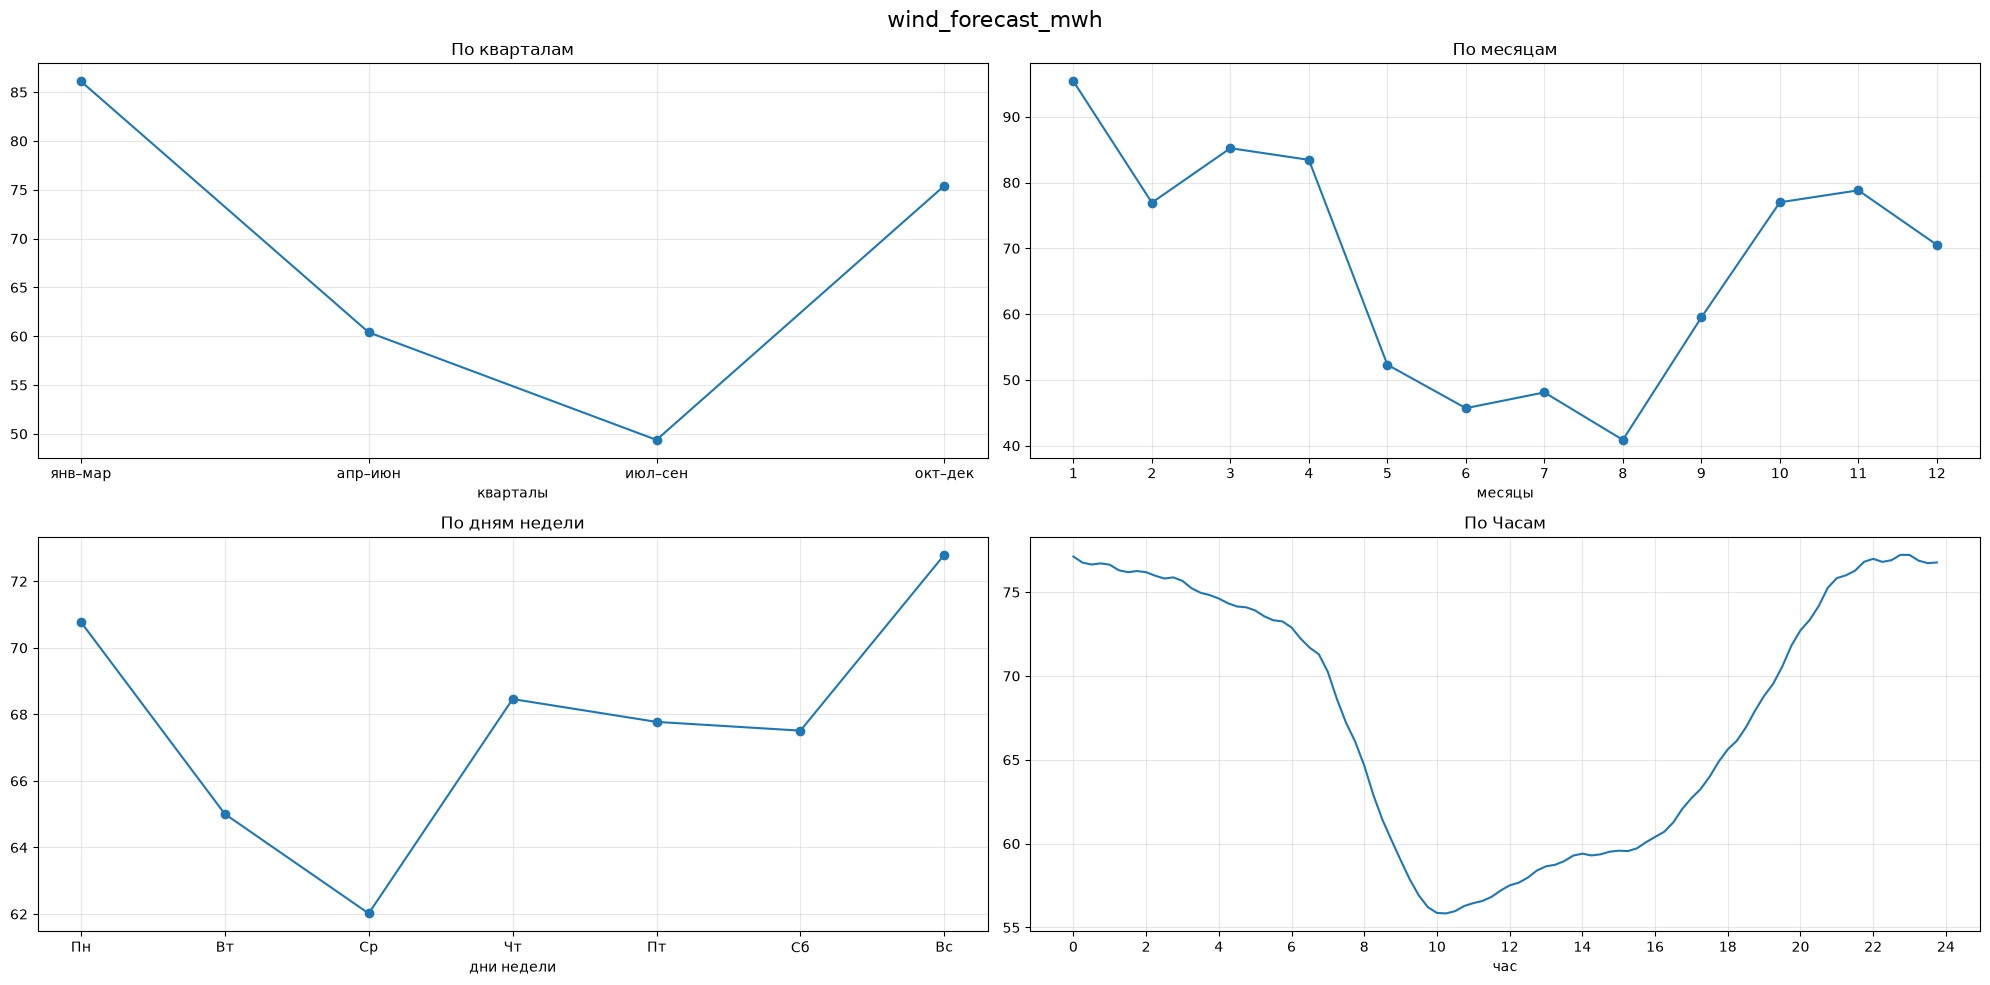

In [170]:
col = X.columns[1]
fig, axes = plt.subplots(2, 2, figsize=(20, 10))

quarter = df['timestamp'].dt.quarter
X[col].groupby(quarter).mean().plot(ax=axes[0, 0], marker='o')
axes[0, 0].set_title('По кварталам')
axes[0, 0].set_xticks([1, 2, 3, 4])
axes[0, 0].set_xlabel('кварталы')
axes[0, 0].set_xticklabels(['янв–мар', 'апр–июн', 'июл–сен', 'окт–дек'])

months = df['timestamp'].dt.month
X[col].groupby(months).mean().plot(ax=axes[0, 1], marker='o')
axes[0, 1].set_title('По месяцам')
axes[0, 1].set_xticks(range(1, 13))
axes[0, 1].set_xlabel('месяцы')

dow = df['timestamp'].dt.day_of_week
X[col].groupby(dow).mean().plot(ax=axes[1, 0], marker='o')
axes[1, 0].set_title('По дням недели')
axes[1, 0].set_xticks(range(7))
axes[1, 0].set_xticklabels(['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс'])
axes[1, 0].set_xlabel('дни недели')

time_of_day = df['timestamp'].dt.hour + df['timestamp'].dt.minute / 60
X[col].groupby(time_of_day).mean().plot(ax=axes[1, 1])
axes[1, 1].set_title('По Часам')
axes[1, 1].set_xticks(range(0, 25, 2))
axes[1, 1].set_xlabel('час')

for ax in axes.flat:
    ax.grid(alpha=0.3)

fig.suptitle(col, fontsize=16)
plt.tight_layout()
plt.show()

*  К вечеру ветронность растет

* 1 квартал более ветренно

* странная просадка в среду

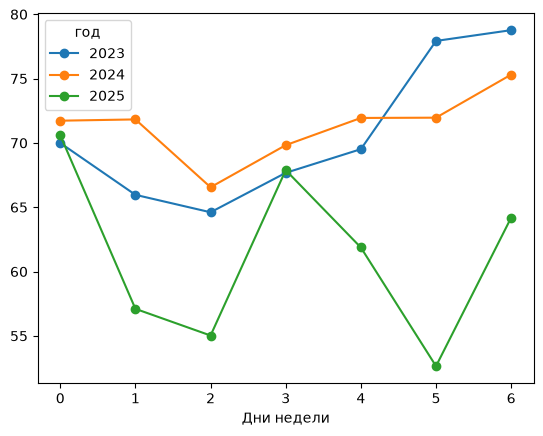

In [171]:
year = df['timestamp'].dt.year
X['wind_forecast_mwh'].groupby([dow, year]).mean().unstack().plot(marker='o')
plt.xlabel('Дни недели')
plt.legend(title='год')
plt.show()

### solar_forecast_mwh

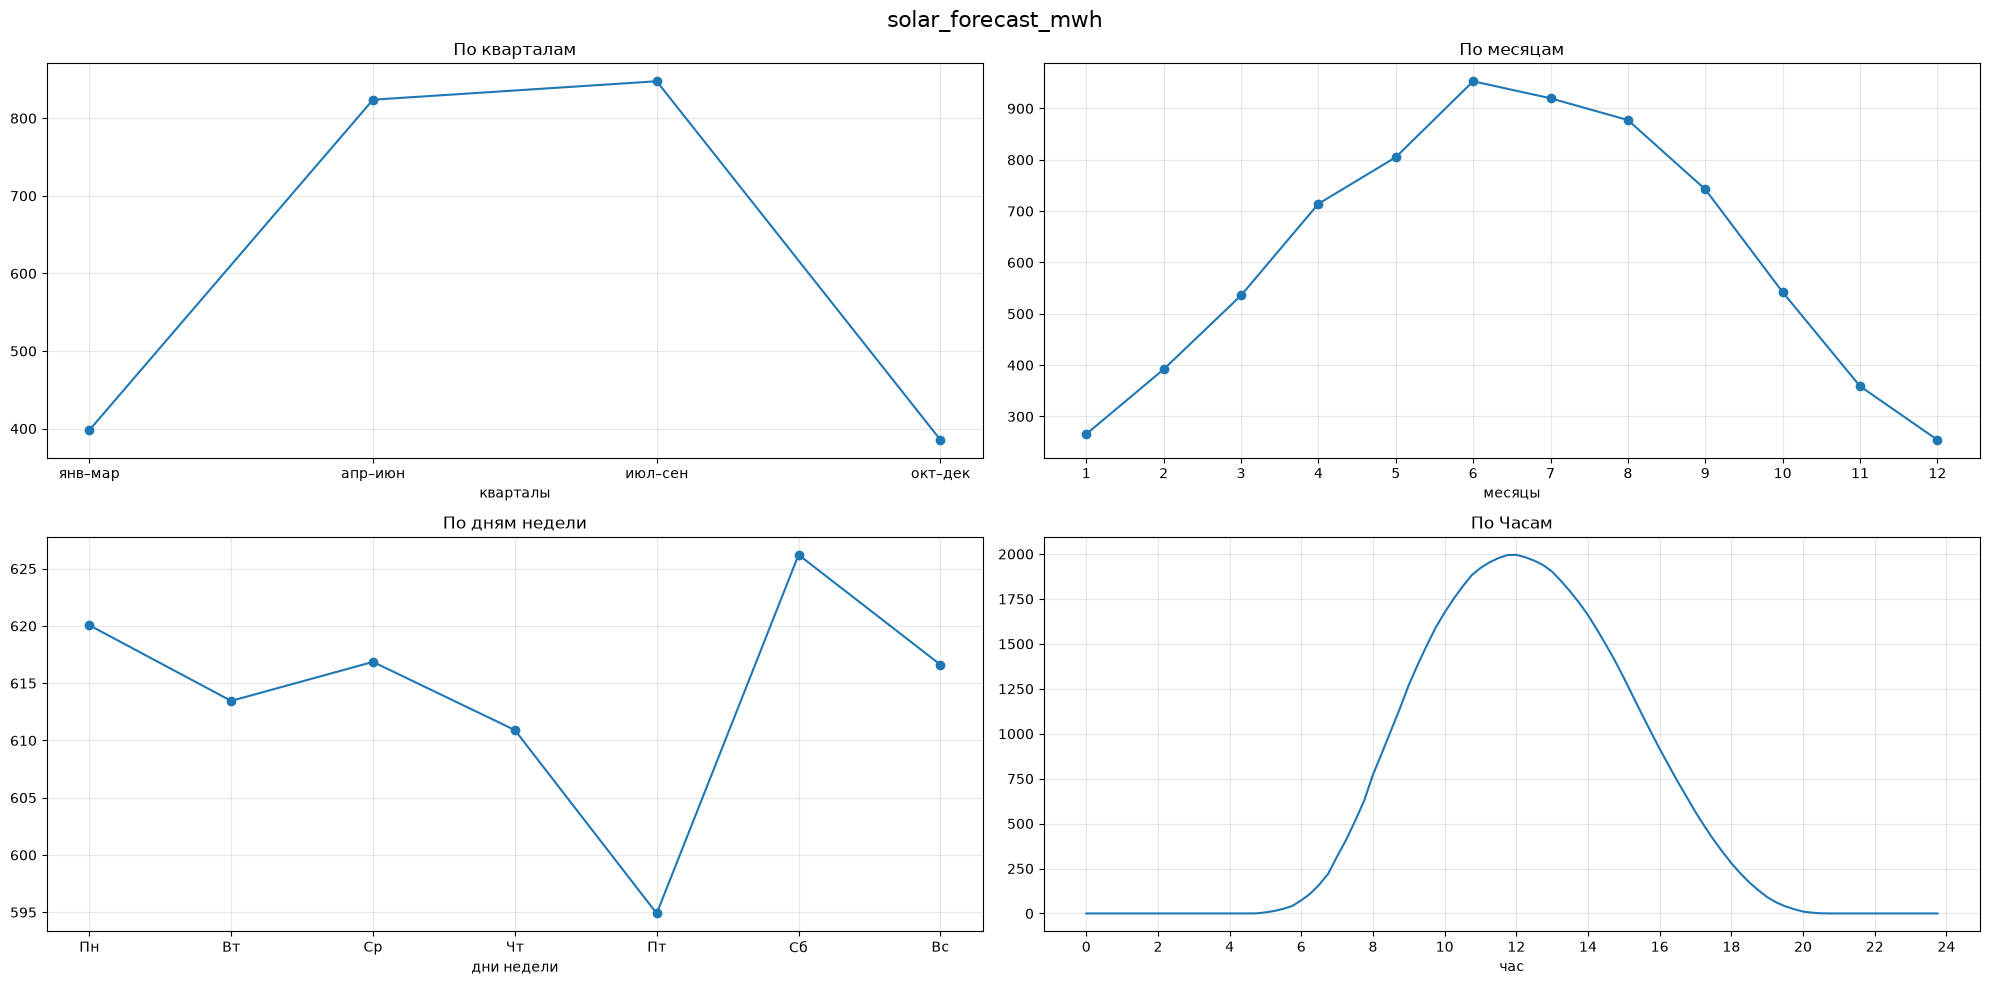

In [172]:
col = X.columns[2]
fig, axes = plt.subplots(2, 2, figsize=(20, 10))

X[col].groupby(quarter).mean().plot(ax=axes[0, 0], marker='o')
axes[0, 0].set_title('По кварталам')
axes[0, 0].set_xticks([1, 2, 3, 4])
axes[0, 0].set_xlabel('кварталы')
axes[0, 0].set_xticklabels(['янв–мар', 'апр–июн', 'июл–сен', 'окт–дек'])

X[col].groupby(months).mean().plot(ax=axes[0, 1], marker='o')
axes[0, 1].set_title('По месяцам')
axes[0, 1].set_xticks(range(1, 13))
axes[0, 1].set_xlabel('месяцы')

X[col].groupby(dow).mean().plot(ax=axes[1, 0], marker='o')
axes[1, 0].set_title('По дням недели')
axes[1, 0].set_xticks(range(7))
axes[1, 0].set_xticklabels(['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс'])
axes[1, 0].set_xlabel('дни недели')

X[col].groupby(time_of_day).mean().plot(ax=axes[1, 1])
axes[1, 1].set_title('По Часам')
axes[1, 1].set_xticks(range(0, 25, 2))
axes[1, 1].set_xlabel('час')

for ax in axes.flat:
    ax.grid(alpha=0.3)

fig.suptitle(col, fontsize=16)
plt.tight_layout()
plt.show()

* зависит от длины солнечных часов (1 и 4 квартал уменьшаются)

* пик в полдень

* в пятницу небольшая просадка

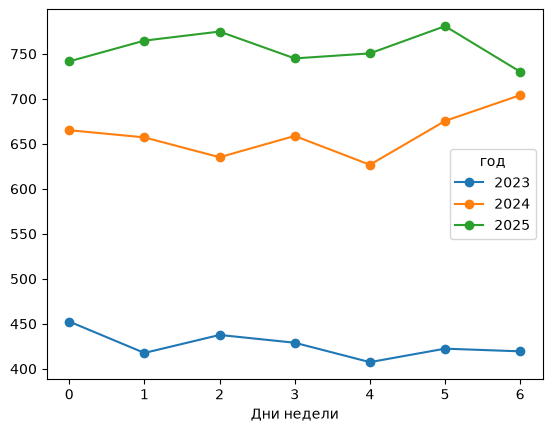

In [173]:
X[X.columns[2]].groupby([dow, year]).mean().unstack().plot(marker='o')
plt.xlabel('Дни недели')
plt.legend(title='год')
plt.show()

В 2023 году было менее ясно 

### nuclear_forecast_mwh

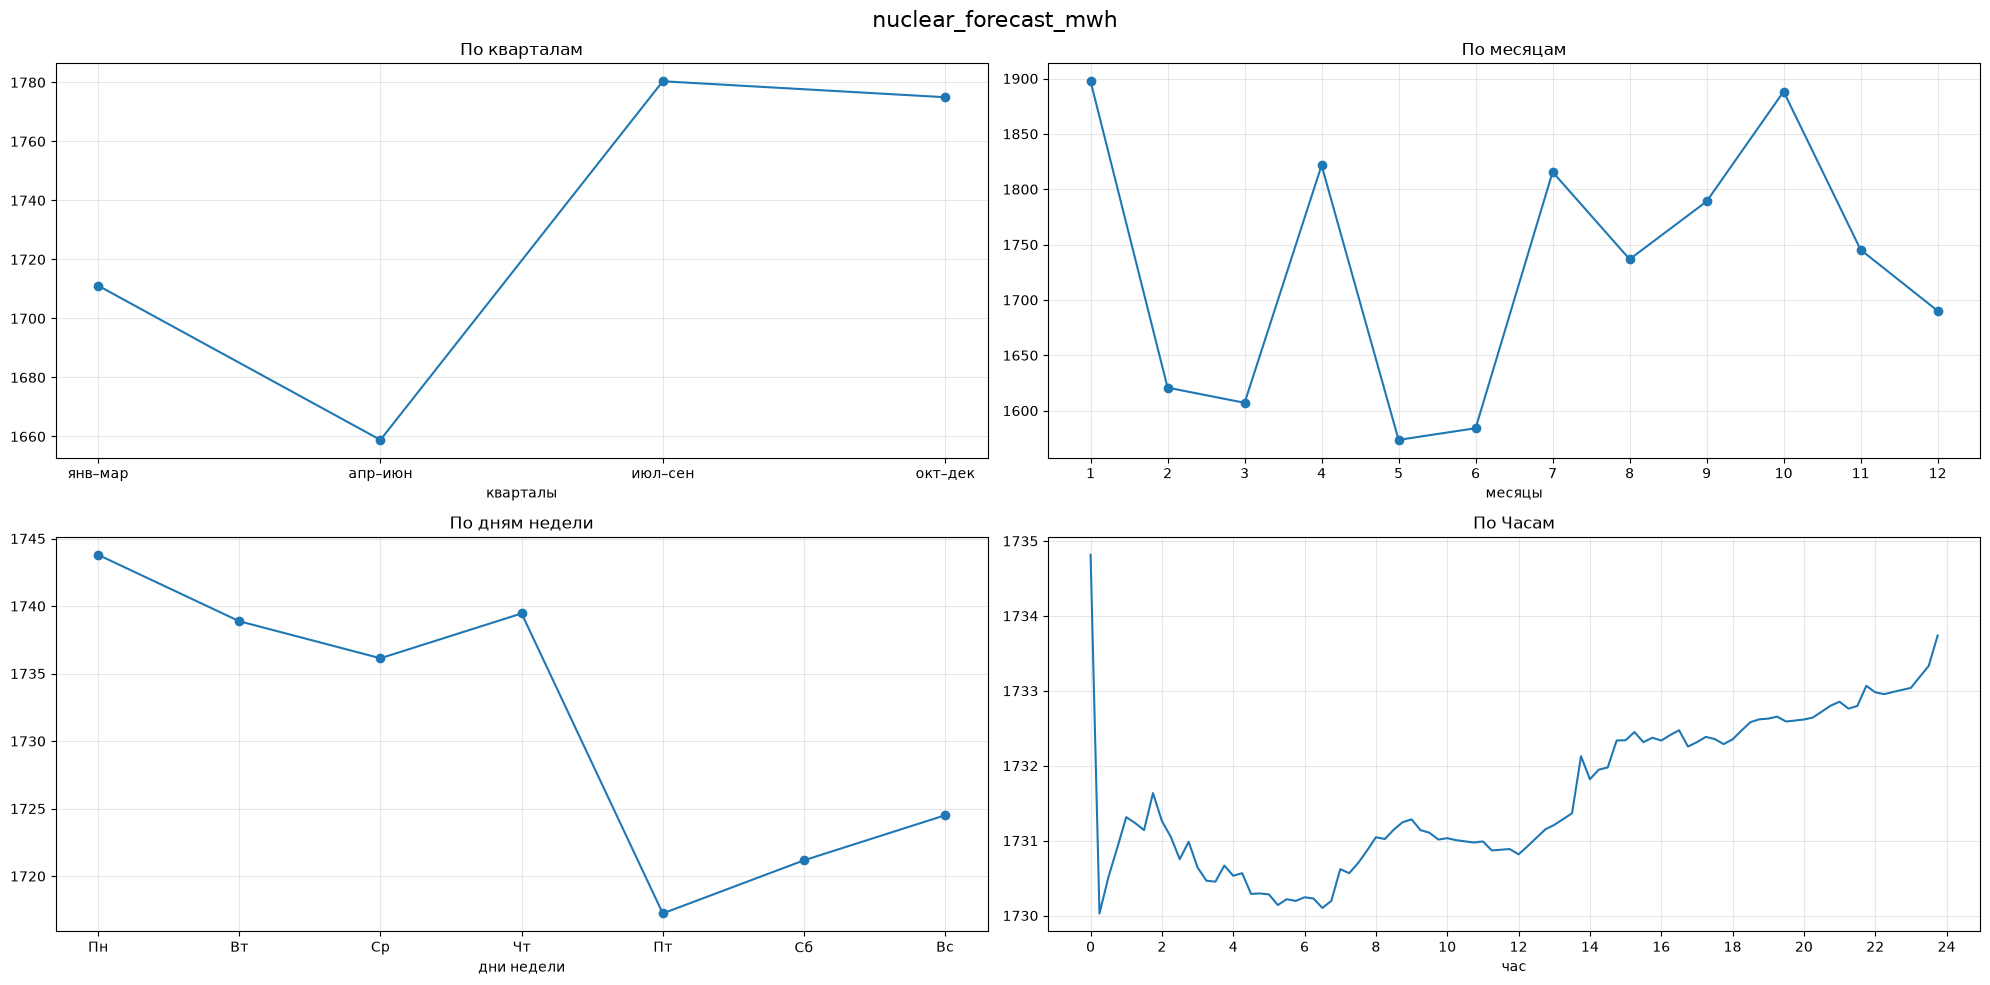

In [174]:
col = X.columns[3]
fig, axes = plt.subplots(2, 2, figsize=(20, 10))

X[col].groupby(quarter).mean().plot(ax=axes[0, 0], marker='o')
axes[0, 0].set_title('По кварталам')
axes[0, 0].set_xticks([1, 2, 3, 4])
axes[0, 0].set_xlabel('кварталы')
axes[0, 0].set_xticklabels(['янв–мар', 'апр–июн', 'июл–сен', 'окт–дек'])

X[col].groupby(months).mean().plot(ax=axes[0, 1], marker='o')
axes[0, 1].set_title('По месяцам')
axes[0, 1].set_xticks(range(1, 13))
axes[0, 1].set_xlabel('месяцы')

X[col].groupby(dow).mean().plot(ax=axes[1, 0], marker='o')
axes[1, 0].set_title('По дням недели')
axes[1, 0].set_xticks(range(7))
axes[1, 0].set_xticklabels(['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс'])
axes[1, 0].set_xlabel('дни недели')

X[col].groupby(time_of_day).mean().plot(ax=axes[1, 1])
axes[1, 1].set_title('По Часам')
axes[1, 1].set_xticks(range(0, 25, 2))
axes[1, 1].set_xlabel('час')

for ax in axes.flat:
    ax.grid(alpha=0.3)

fig.suptitle(col, fontsize=16)
plt.tight_layout()
plt.show()

### temperature_forecast_c

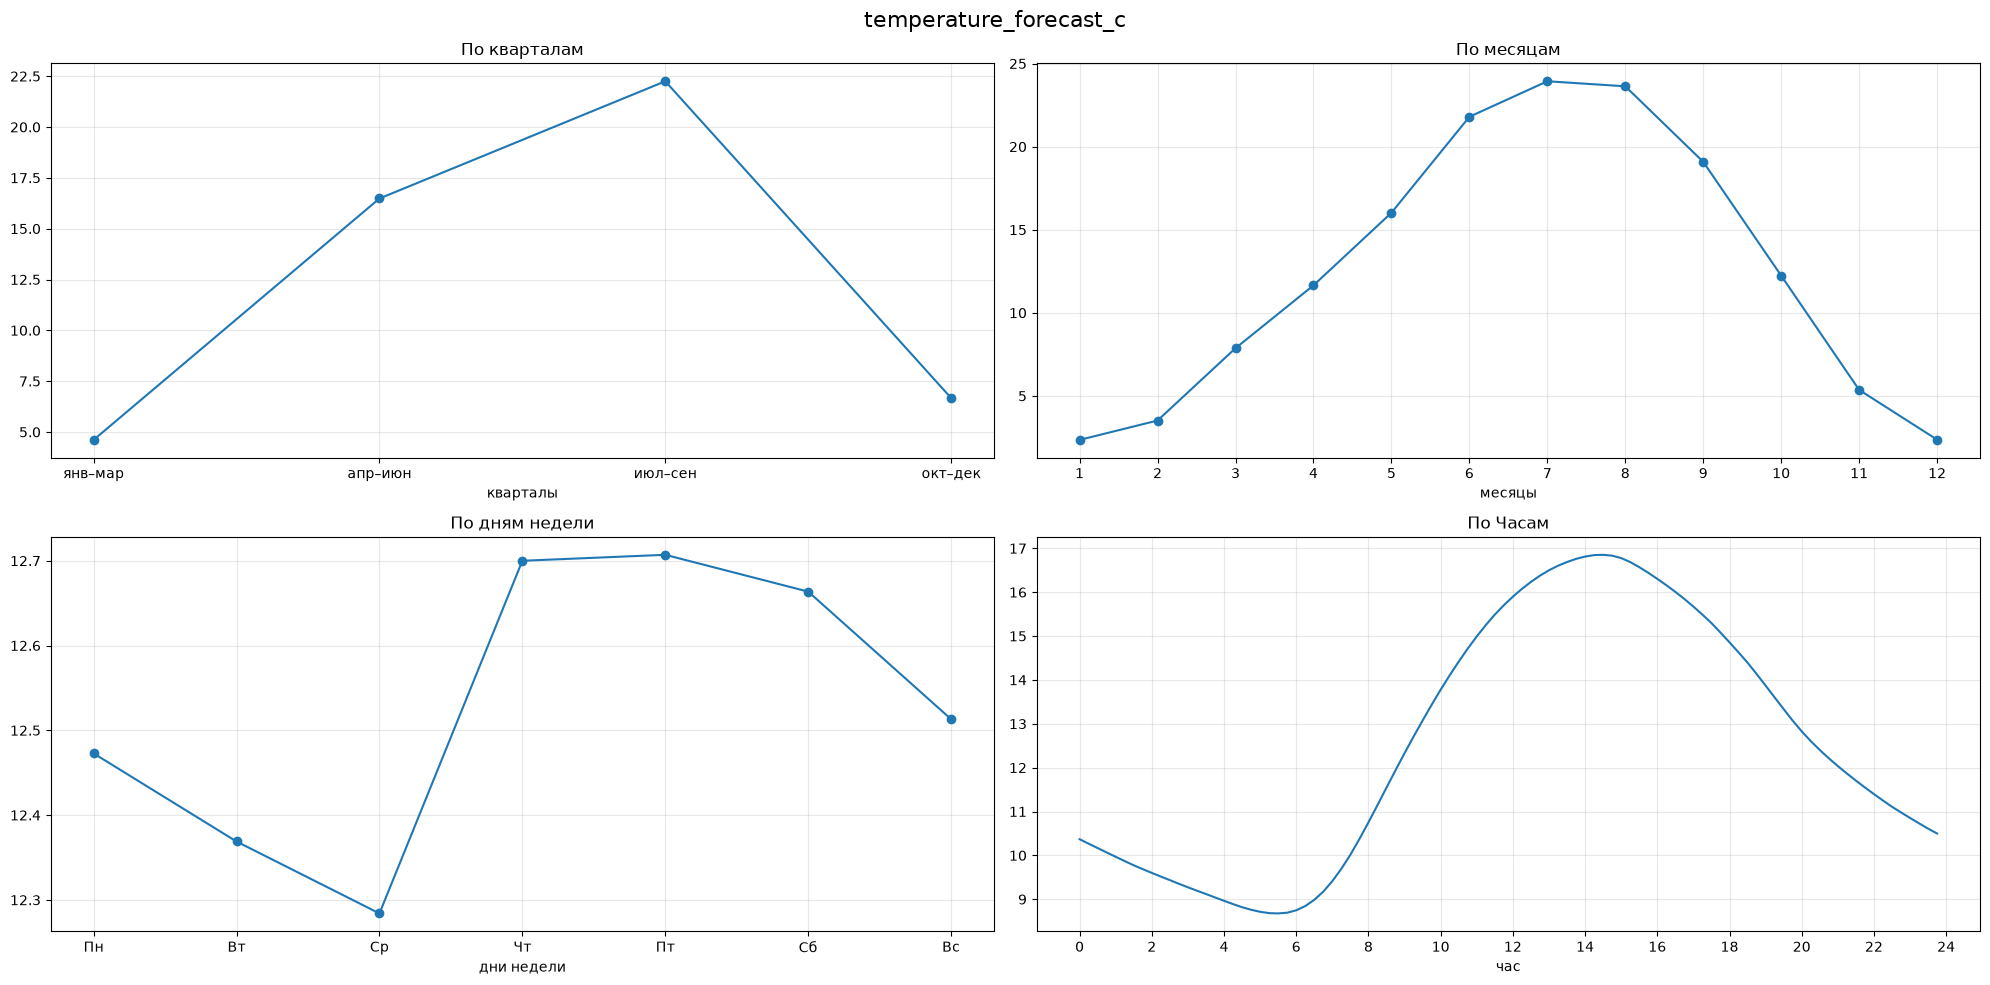

In [175]:
col = X.columns[4]
fig, axes = plt.subplots(2, 2, figsize=(20, 10))

X[col].groupby(quarter).mean().plot(ax=axes[0, 0], marker='o')
axes[0, 0].set_title('По кварталам')
axes[0, 0].set_xticks([1, 2, 3, 4])
axes[0, 0].set_xlabel('кварталы')
axes[0, 0].set_xticklabels(['янв–мар', 'апр–июн', 'июл–сен', 'окт–дек'])

X[col].groupby(months).mean().plot(ax=axes[0, 1], marker='o')
axes[0, 1].set_title('По месяцам')
axes[0, 1].set_xticks(range(1, 13))
axes[0, 1].set_xlabel('месяцы')

X[col].groupby(dow).mean().plot(ax=axes[1, 0], marker='o')
axes[1, 0].set_title('По дням недели')
axes[1, 0].set_xticks(range(7))
axes[1, 0].set_xticklabels(['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс'])
axes[1, 0].set_xlabel('дни недели')

X[col].groupby(time_of_day).mean().plot(ax=axes[1, 1])
axes[1, 1].set_title('По Часам')
axes[1, 1].set_xticks(range(0, 25, 2))
axes[1, 1].set_xlabel('час')

for ax in axes.flat:
    ax.grid(alpha=0.3)

fig.suptitle(col, fontsize=16)
plt.tight_layout()
plt.show()

### net_exchange_forecast_mwh

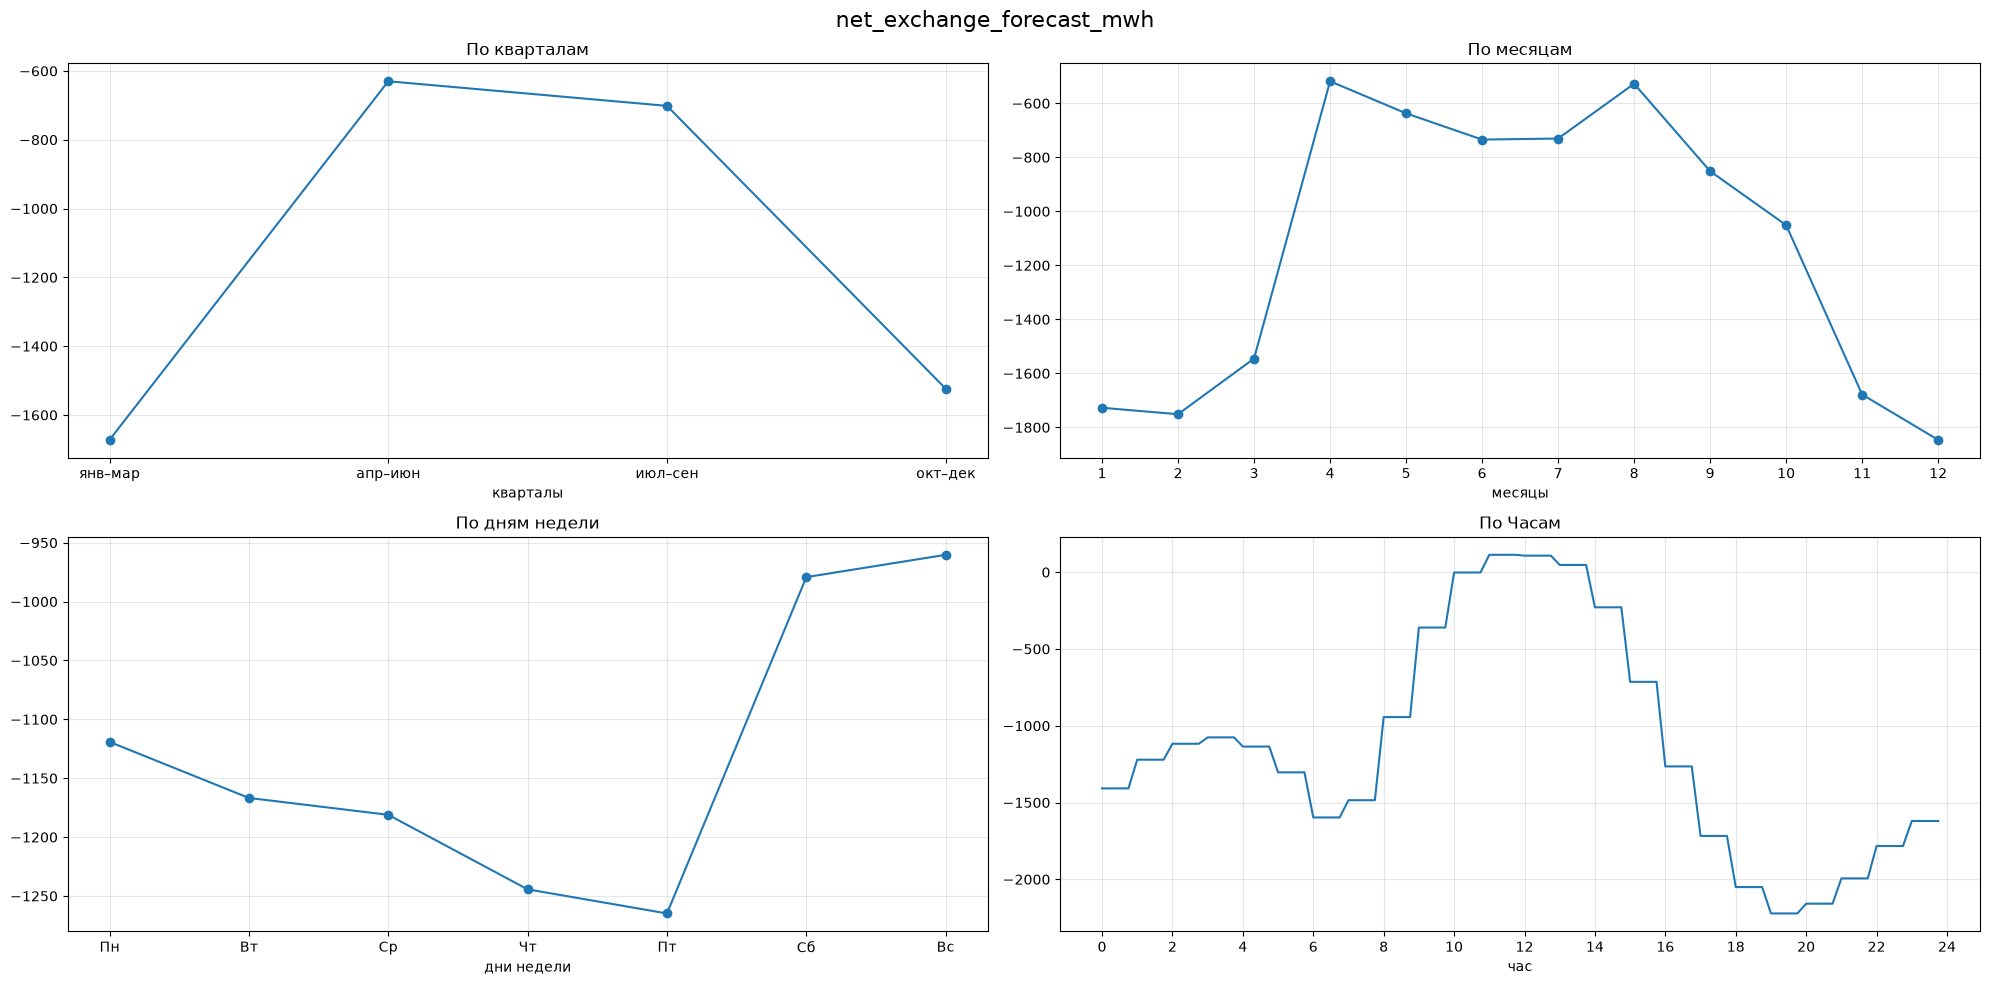

In [176]:
col = X.columns[5]
fig, axes = plt.subplots(2, 2, figsize=(20, 10))

X[col].groupby(quarter).mean().plot(ax=axes[0, 0], marker='o')
axes[0, 0].set_title('По кварталам')
axes[0, 0].set_xticks([1, 2, 3, 4])
axes[0, 0].set_xlabel('кварталы')
axes[0, 0].set_xticklabels(['янв–мар', 'апр–июн', 'июл–сен', 'окт–дек'])

X[col].groupby(months).mean().plot(ax=axes[0, 1], marker='o')
axes[0, 1].set_title('По месяцам')
axes[0, 1].set_xticks(range(1, 13))
axes[0, 1].set_xlabel('месяцы')

X[col].groupby(dow).mean().plot(ax=axes[1, 0], marker='o')
axes[1, 0].set_title('По дням недели')
axes[1, 0].set_xticks(range(7))
axes[1, 0].set_xticklabels(['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс'])
axes[1, 0].set_xlabel('дни недели')

X[col].groupby(time_of_day).mean().plot(ax=axes[1, 1])
axes[1, 1].set_title('По Часам')
axes[1, 1].set_xticks(range(0, 25, 2))
axes[1, 1].set_xlabel('час')

for ax in axes.flat:
    ax.grid(alpha=0.3)

fig.suptitle(col, fontsize=16)
plt.tight_layout()
plt.show()

На выходных меньше импортируют (2 и 3 квартал тоже)



### Целевая переменная

In [177]:
y = df['QH_WAP']
y.describe()

count    105122.000000
mean        107.527928
std          82.040454
min        -561.850000
25%          69.430000
50%          99.440000
75%         135.340000
max        6326.670000
Name: QH_WAP, dtype: float64

Заметим:
* минимальное значение -561 что странно так как 25 % квартиль 69 - значит какой то резкий спад будет


Если это не выброс то - цена была отрицательная и объем был маленький


* такая же история с max 6326 хотя 75% квартиль всего 135


Тут тоже объем был малеьнкий но цена большая


Заполним пропуски в целевой переменной медианной ценой за то же время суток

In [178]:
df['QH_WAP'] = df['QH_WAP'].fillna(df['QH_WAP'].groupby(time_of_day).transform('median'))

In [179]:
y = df['QH_WAP']
y.describe()

count    105216.000000
mean        107.513966
std          82.005965
min        -561.850000
25%          69.460000
50%          99.410000
75%         135.300000
max        6326.670000
Name: QH_WAP, dtype: float64

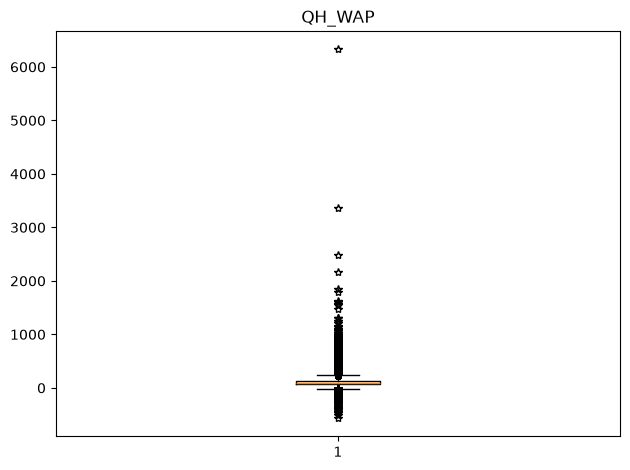

In [180]:
plt.boxplot(y, sym='*')
plt.title("QH_WAP")
plt.tight_layout()
plt.show()

In [181]:
Q1 = df['QH_WAP'].quantile(0.2)
Q3 = df['QH_WAP'].quantile(0.75)
IQR = Q3 - Q1

lower_us = Q1 - 1.5 * IQR
higer_us = Q3 + 1.5 * IQR

beyond = df[(df['QH_WAP'] < lower_us) | (df['QH_WAP'] > higer_us)]
print(f'Количество аномальных значений: {len(beyond)}')
print(f'Их процент: {len(beyond) / len(df) * 100:.2f}%')

Количество аномальных значений: 4118
Их процент: 3.91%


### Rolling Z-score

In [182]:
price = df['QH_WAP']
window = 96                                        
past = price.shift(1)                               
rolling_mean = past.rolling(window, min_periods=window // 2).mean()
rolling_std  = past.rolling(window, min_periods=window // 2).std()
z = (price - rolling_mean) / rolling_std

anomalies = z.abs() > 3
print(f'Аномалий: {anomalies.sum()}')

Аномалий: 1481


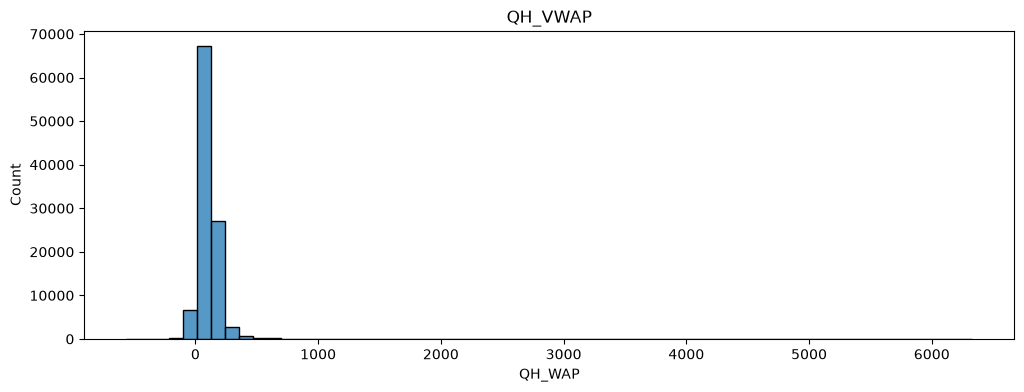

In [183]:
plt.figure(figsize=(12, 4))
sns.histplot(y, bins=60)
plt.title('QH_VWAP')
plt.show()

Основная масса цен лежит в диапозоне примерно [-200, 400], но график широкий может это и есть эти выбросы

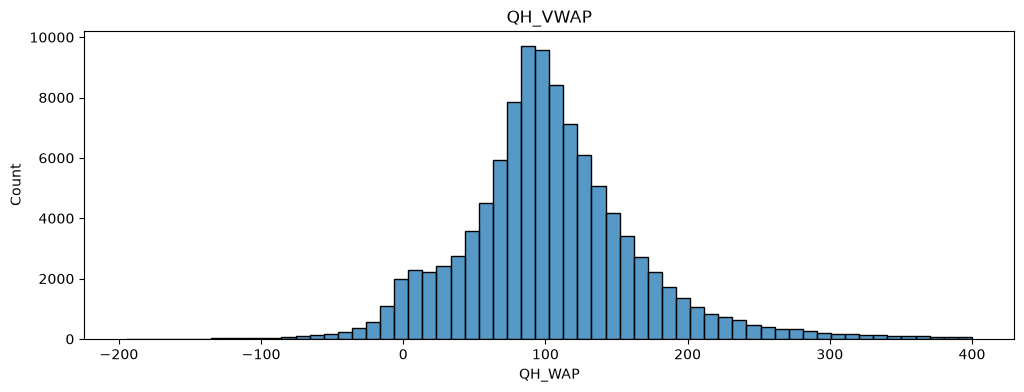

In [184]:
plt.figure(figsize=(12, 4))
sns.histplot(y[y.between(-200,400)], bins=60)
plt.title('QH_VWAP')
plt.show()

Надо посмотреть по часам есть ли у данных больших значений какой либо причина или это выброс // сбой какой то

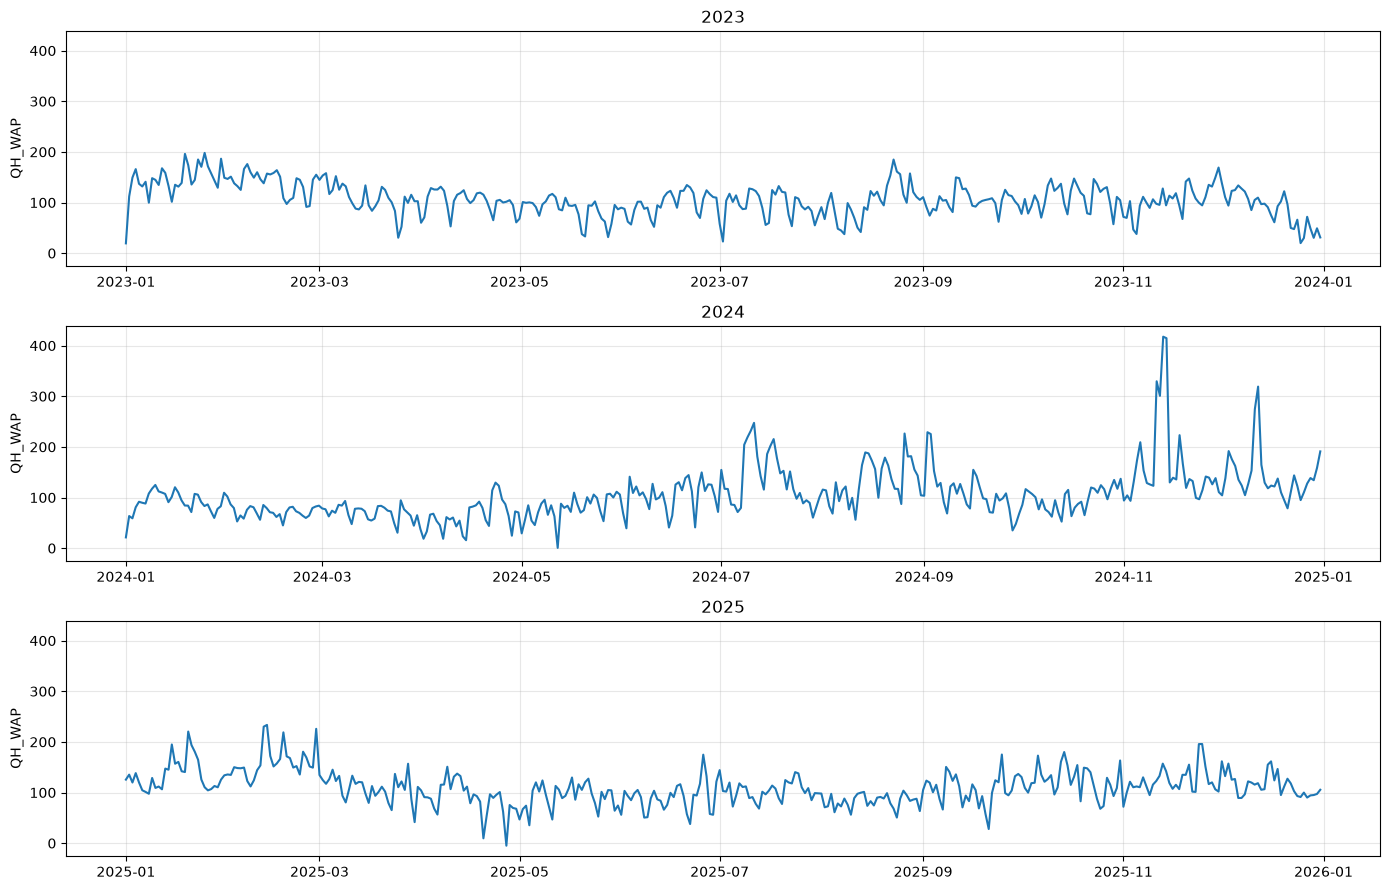

In [185]:
# посмотрим в изменения цен в течении 3 лет отельно в каждый год
fig, axes = plt.subplots(len(years), 1, figsize=(14, 3 * len(years)), sharey=True)

for ax, year in zip(axes, years):
    d = df[df['timestamp'].dt.year == year]
    day = d.set_index('timestamp')['QH_WAP'].resample('D').mean()
    ax.plot(day.index, day.values)
    ax.set_title(f'{year}')
    ax.set_ylabel('QH_WAP')
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

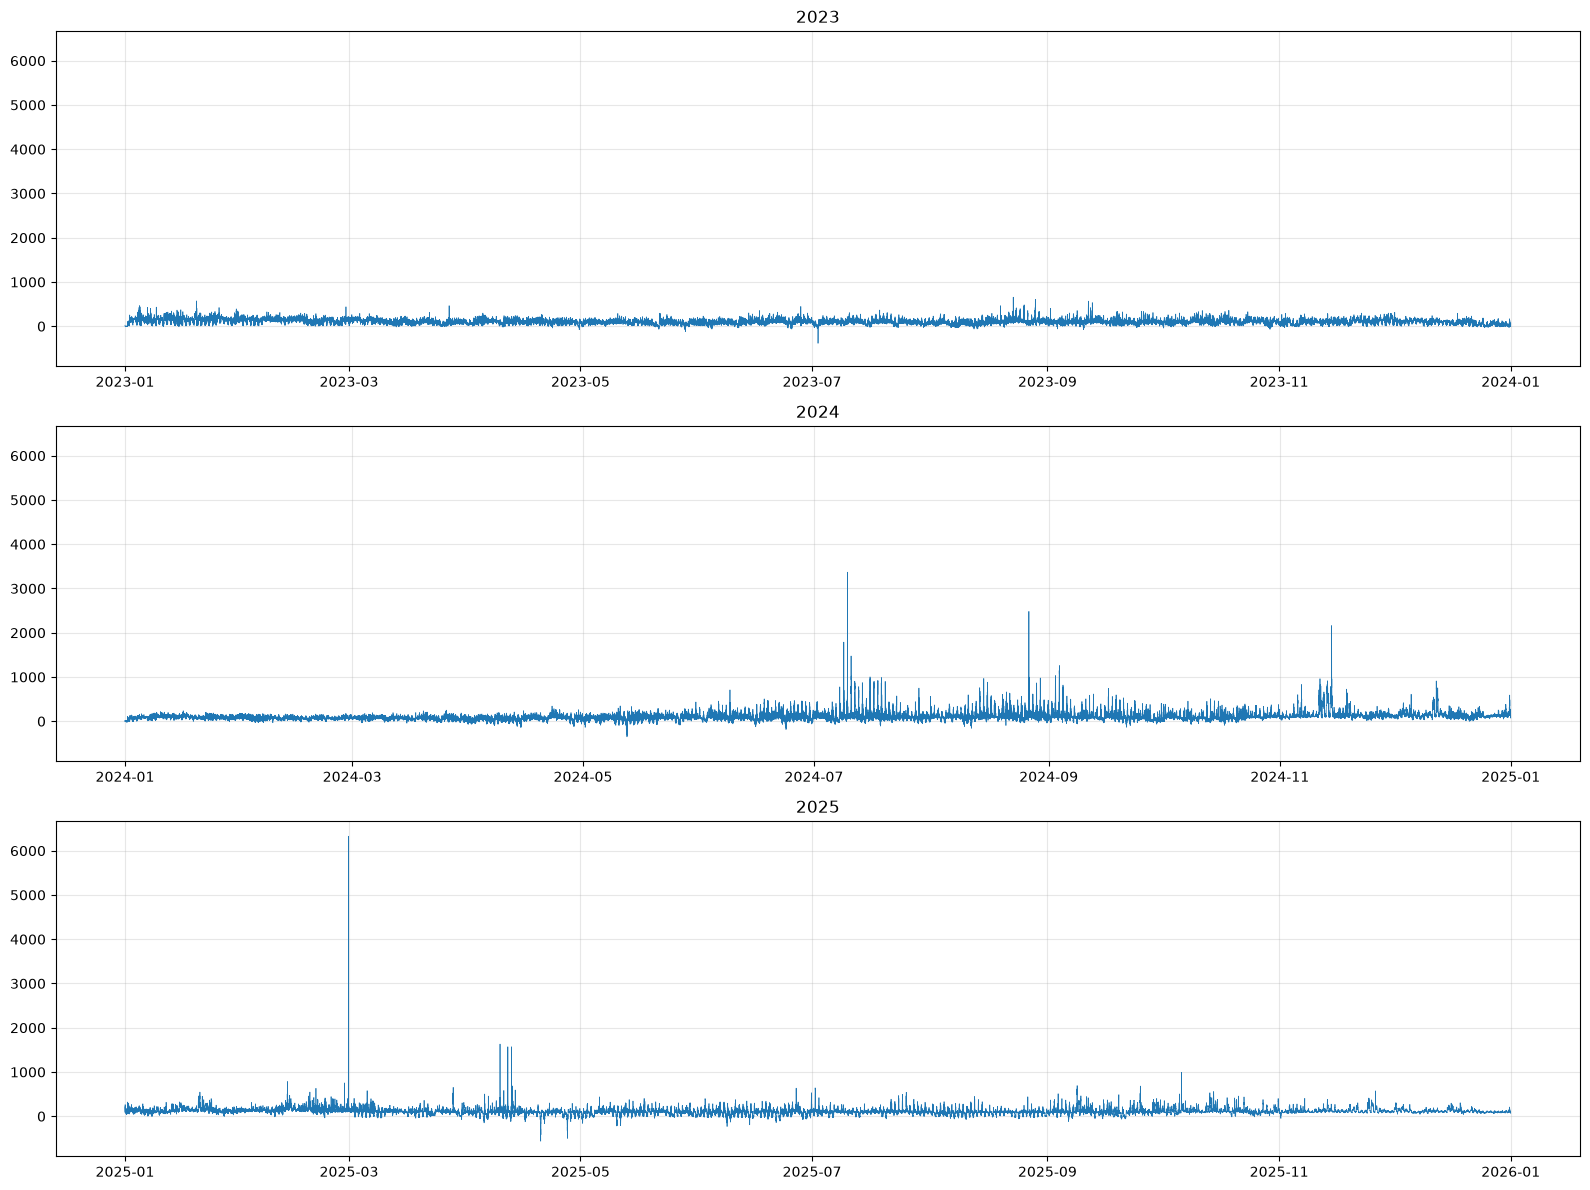

In [186]:
fig, axes = plt.subplots(len(years), 1, figsize=(16, 12), sharey=True)

for ax, year in zip(axes, years):
    d = df[df['timestamp'].dt.year == year]
    ax.plot(d['timestamp'], d['QH_WAP'], linewidth=0.5)
    ax.set_title(f'{year}') 
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [187]:
filtered_df = df[df['QH_WAP'] > 1000]
filtered_df

,timestamp,QH_WAP,demand_forecast_mwh,wind_forecast_mwh,solar_forecast_mwh,nuclear_forecast_mwh,temperature_forecast_c,net_exchange_forecast_mwh
53259,2024-07-08 19:45:00+02:00,1300.29,5651.6,25.2,142.1,1900.0,27.36,-600.0
53264,2024-07-08 21:00:00+02:00,1542.99,5761.9,31.3,0.0,1900.0,25.35,-600.0
53265,2024-07-08 21:15:00+02:00,1788.02,5748.6,33.0,0.0,1900.0,25.02,-600.0
53358,2024-07-09 20:30:00+02:00,1602.18,5818.2,9.1,5.9,1900.0,27.79,-600.0
53359,2024-07-09 20:45:00+02:00,1298.77,5851.9,10.0,0.0,1900.0,27.32,-600.0
53361,2024-07-09 21:15:00+02:00,3367.91,5887.3,10.9,0.0,1900.0,26.65,-600.0
53450,2024-07-10 19:30:00+02:00,1475.00,6263.3,7.6,175.7,1900.0,31.24,-600.0
53451,2024-07-10 19:45:00+02:00,1149.28,6326.3,7.3,118.8,1900.0,30.72,-600.0
53454,2024-07-10 20:30:00+02:00,1019.63,6343.6,11.7,4.3,1900.0,29.30,-600.0
53931,2024-07-15 19:45:00+02:00,1002.28,6540.6,13.8,130.7,1900.0,30.08,-600.0


выглядит как выброс и слишком выбивается 2025-02-28 


2023 год выглядит стабильно не каких перекосов - просто стабильные цены

2024 почему то с 7 месяца  значения целевой переменной резко появились скачки  

2025 год как на протяжении всего года есть резкие скачки 

В дальнейшем посмотрим на эти периоды и на даты в интервалах

In [188]:
high = df['QH_WAP'].quantile(0.99)
low = df['QH_WAP'].quantile(0.01)
print(f'Нижний порог {low}')
print(f'Верхний порог {high}')
anomalies_h = df[df['QH_WAP'] > high]
anomalies_l = df[df['QH_WAP'] < low]




Нижний порог -29.509499999999992
Верхний порог 377.66400000000027


In [189]:

anomalies = df[df['QH_WAP'] > 1000]
anomalies['timestamp'].dt.date.value_counts().sort_index()

timestamp
2024-07-08    3
2024-07-09    3
2024-07-10    3
2024-07-15    1
2024-08-26    2
2024-09-02    2
2024-09-03    5
2024-11-14    4
2025-02-28    1
2025-04-09    1
2025-04-11    1
2025-04-12    4
Name: count, dtype: int64

В отличие от других дат когда тренд на высокую стоимость был несколько дней подряд или с пропуском в один день - 2025-02-2 одинокий (это похоже очень на выброс)


# Сезонность целевой переменной

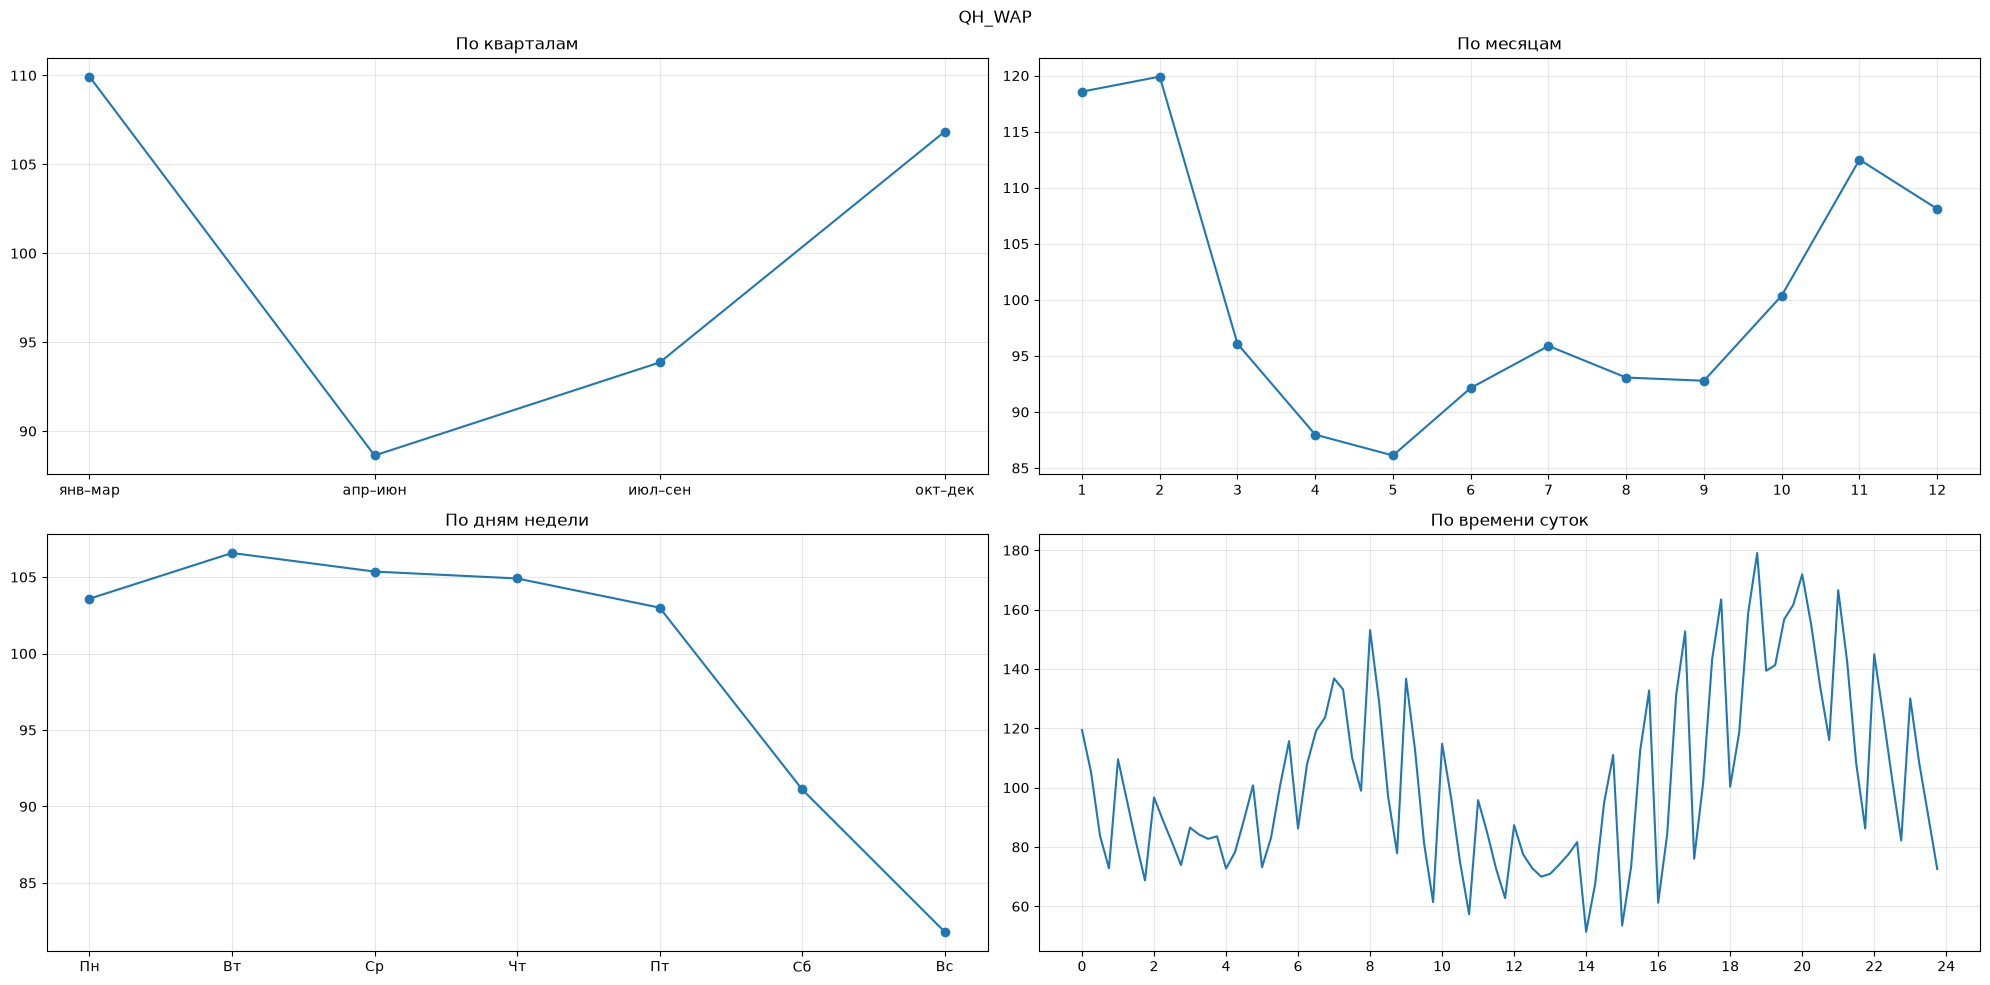

In [190]:
fig, axes = plt.subplots(2, 2, figsize=(20, 10))

p = y.groupby(quarter).median()
axes[0, 0].plot(p.index, p.values, marker='o')
axes[0, 0].set_title('По кварталам')
axes[0, 0].set_xticks([1, 2, 3, 4])
axes[0, 0].set_xticklabels(['янв–мар', 'апр–июн', 'июл–сен', 'окт–дек'])


p = y.groupby(months).median()
axes[0, 1].plot(p.index, p.values, marker='o')
axes[0, 1].set_title('По месяцам')
axes[0, 1].set_xticks(range(1, 13))


p = y.groupby(dow).median()
axes[1, 0].plot(p.index, p.values, marker='o')
axes[1, 0].set_title('По дням недели')
axes[1, 0].set_xticks(range(7))
axes[1, 0].set_xticklabels(['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс'])


p = y.groupby(time_of_day).median()
axes[1, 1].plot(p.index, p.values)
axes[1, 1].set_title('По времени суток')
axes[1, 1].set_xticks(range(0, 25, 2))


for ax in axes.flat:
    ax.grid(alpha=0.3)

fig.suptitle('QH_WAP')
plt.tight_layout()
plt.show()

цена растет к вечеру

падает к выходным

растет к 1 кварталу 

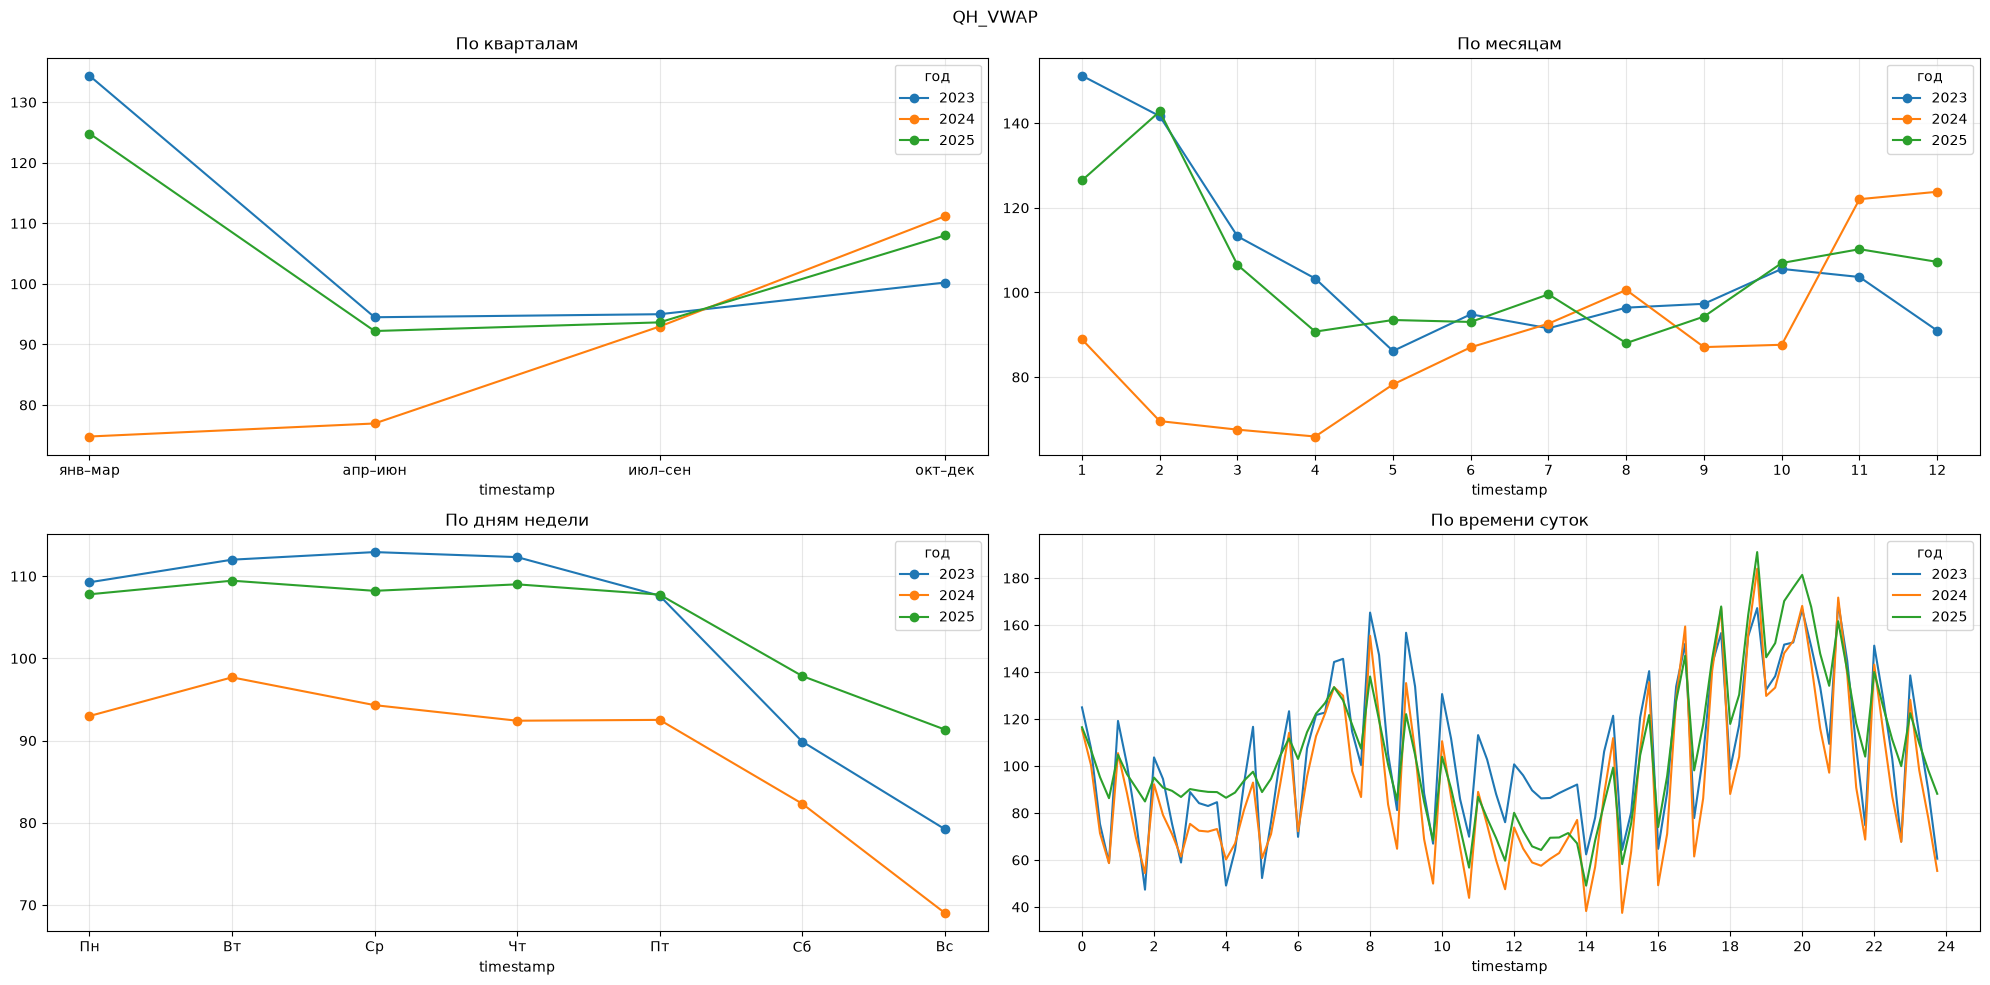

In [191]:
year = df['timestamp'].dt.year

fig, axes = plt.subplots(2, 2, figsize=(20, 10))

y.groupby([quarter, year]).median().unstack().plot(ax=axes[0, 0], marker='o')
axes[0, 0].set_title('По кварталам')
axes[0, 0].set_xticks([1, 2, 3, 4])
axes[0, 0].set_xticklabels(['янв–мар', 'апр–июн', 'июл–сен', 'окт–дек'])
axes[0, 0].legend(title='год')

y.groupby([months, year]).median().unstack().plot(ax=axes[0, 1], marker='o')
axes[0, 1].set_title('По месяцам')
axes[0, 1].set_xticks(range(1, 13))
axes[0, 1].legend(title='год')

y.groupby([dow, year]).median().unstack().plot(ax=axes[1, 0], marker='o')
axes[1, 0].set_title('По дням недели')
axes[1, 0].set_xticks(range(7))
axes[1, 0].set_xticklabels(['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс'])
axes[1, 0].legend(title='год')

y.groupby([time_of_day, year]).median().unstack().plot(ax=axes[1, 1])
axes[1, 1].set_title('По времени суток')
axes[1, 1].set_xticks(range(0, 25, 2))
axes[1, 1].legend(title='год')

for ax in axes.flat:
    ax.grid(alpha=0.3)

fig.suptitle('QH_VWAP')
plt.tight_layout()
plt.show()

года сильно разняться на длительных отрезках

Обрежем данные и посомтрим на эти графики

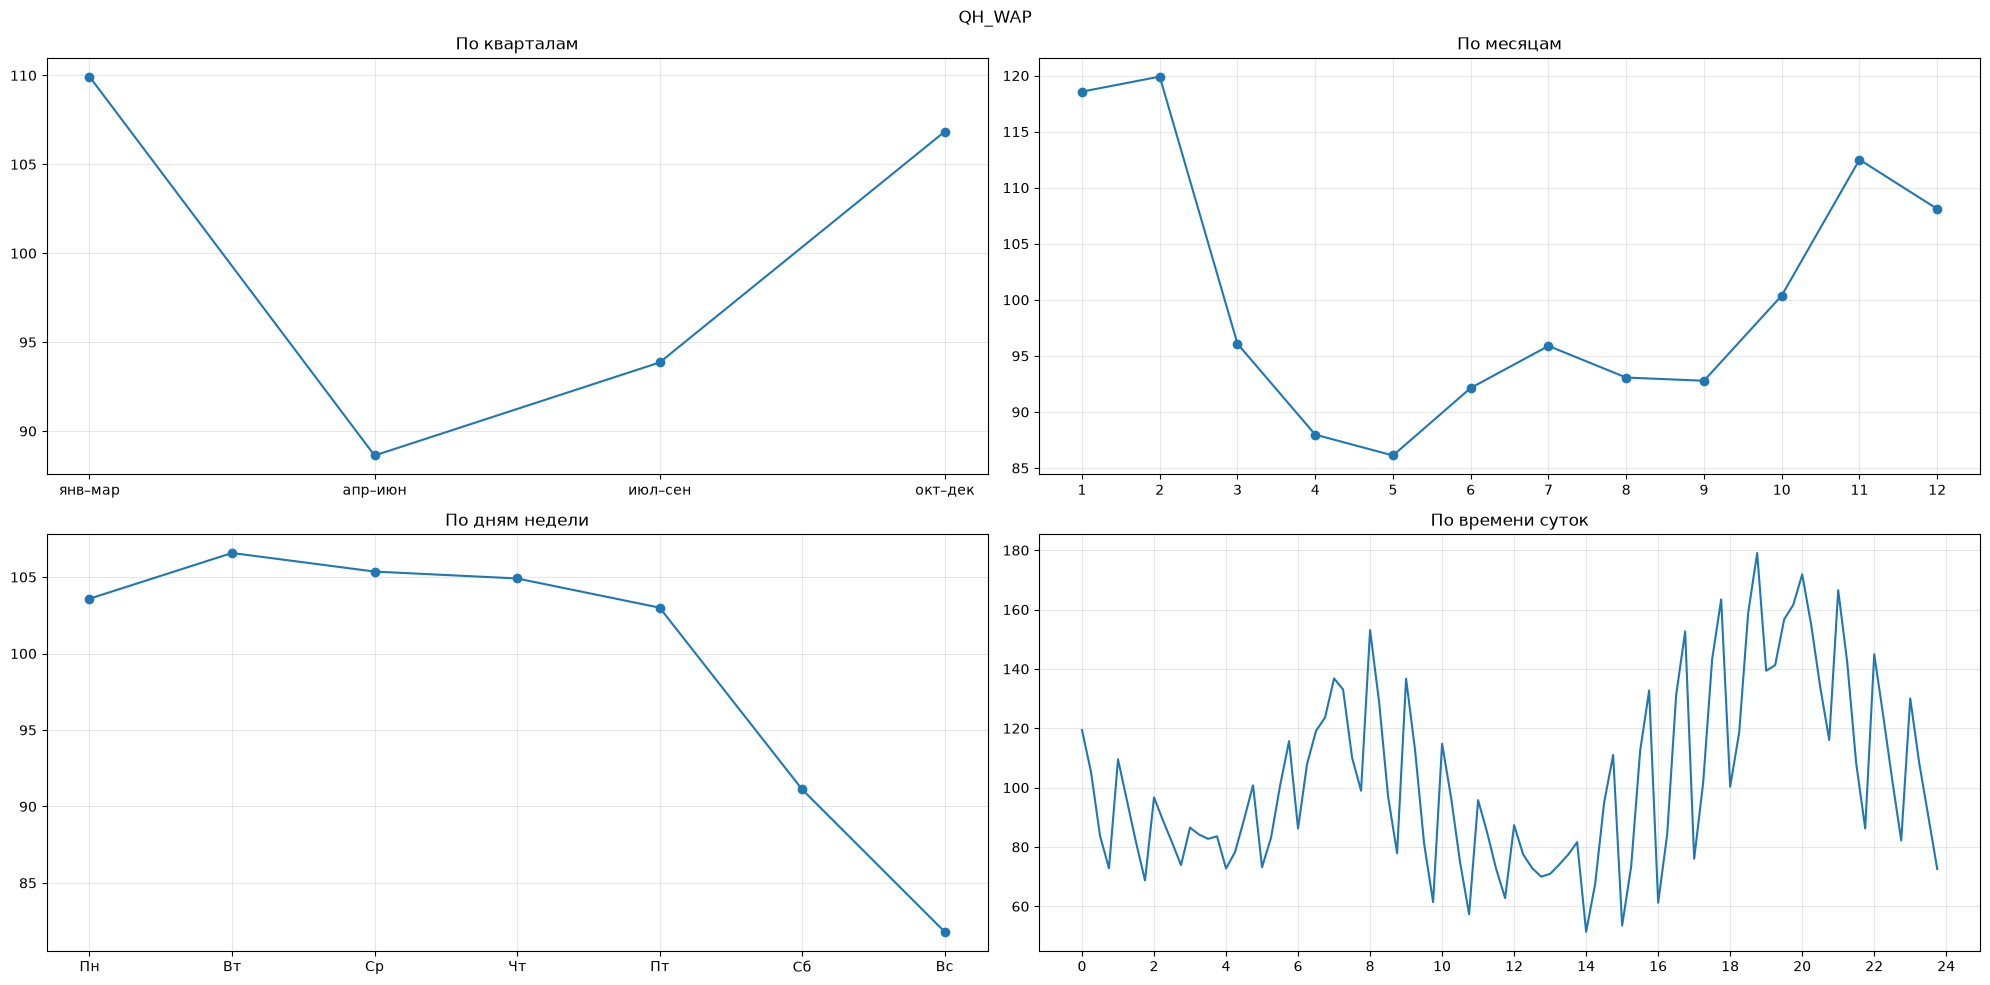

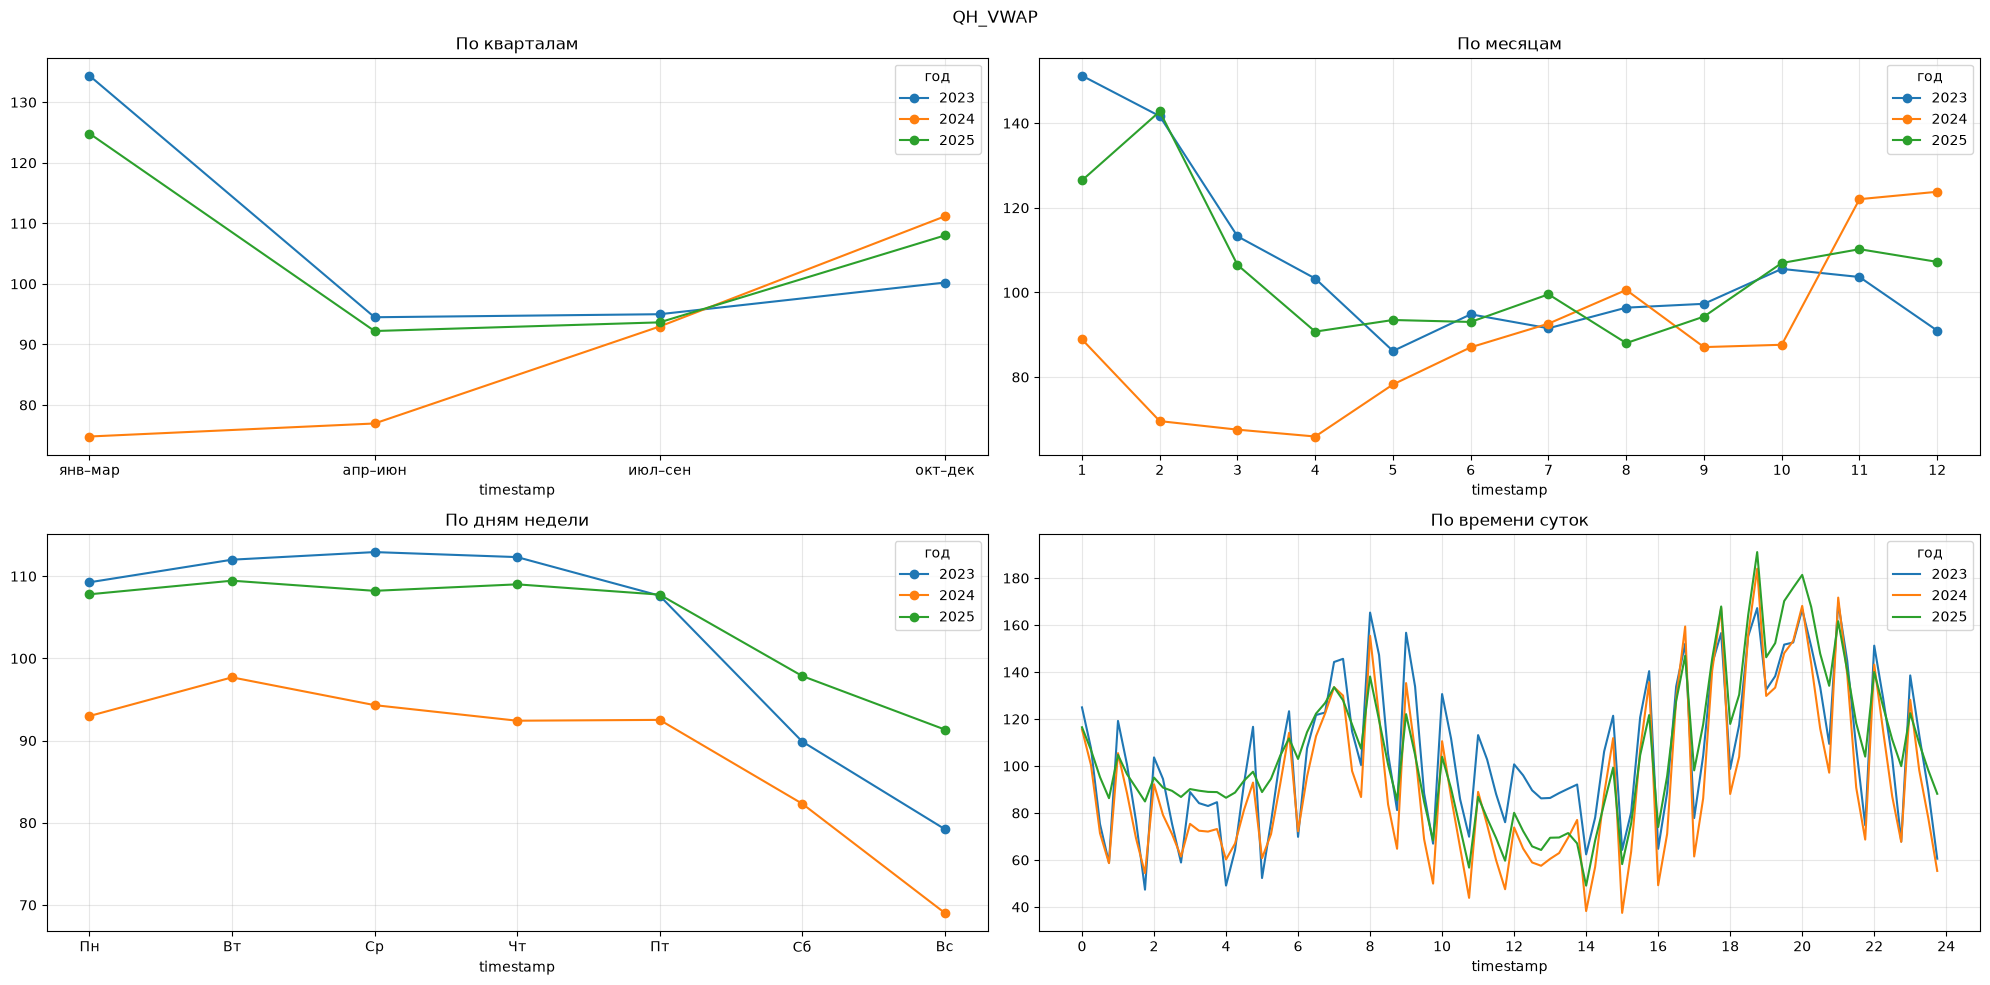

In [192]:
y_clip = df['QH_WAP'].clip(upper=df['QH_WAP'].quantile(0.99), lower=df['QH_WAP'].quantile(0.01))
df['QH_WAP'] = y_clip



fig, axes = plt.subplots(2, 2, figsize=(20, 10))

p = y_clip.groupby(quarter).median()
axes[0, 0].plot(p.index, p.values, marker='o')
axes[0, 0].set_title('По кварталам')
axes[0, 0].set_xticks([1, 2, 3, 4])
axes[0, 0].set_xticklabels(['янв–мар', 'апр–июн', 'июл–сен', 'окт–дек'])


p = y_clip.groupby(months).median()
axes[0, 1].plot(p.index, p.values, marker='o')
axes[0, 1].set_title('По месяцам')
axes[0, 1].set_xticks(range(1, 13))


p = y_clip.groupby(dow).median()
axes[1, 0].plot(p.index, p.values, marker='o')
axes[1, 0].set_title('По дням недели')
axes[1, 0].set_xticks(range(7))
axes[1, 0].set_xticklabels(['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс'])


p = y_clip.groupby(time_of_day).median()
axes[1, 1].plot(p.index, p.values)
axes[1, 1].set_title('По времени суток')
axes[1, 1].set_xticks(range(0, 25, 2))


for ax in axes.flat:
    ax.grid(alpha=0.3)

fig.suptitle('QH_WAP')
plt.tight_layout()
plt.show()

year = df['timestamp'].dt.year

fig, axes = plt.subplots(2, 2, figsize=(20, 10))

y_clip.groupby([quarter, year]).median().unstack().plot(ax=axes[0, 0], marker='o')
axes[0, 0].set_title('По кварталам')
axes[0, 0].set_xticks([1, 2, 3, 4])
axes[0, 0].set_xticklabels(['янв–мар', 'апр–июн', 'июл–сен', 'окт–дек'])
axes[0, 0].legend(title='год')

y_clip.groupby([months, year]).median().unstack().plot(ax=axes[0, 1], marker='o')
axes[0, 1].set_title('По месяцам')
axes[0, 1].set_xticks(range(1, 13))
axes[0, 1].legend(title='год')

y_clip.groupby([dow, year]).median().unstack().plot(ax=axes[1, 0], marker='o')
axes[1, 0].set_title('По дням недели')
axes[1, 0].set_xticks(range(7))
axes[1, 0].set_xticklabels(['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс'])
axes[1, 0].legend(title='год')

y_clip.groupby([time_of_day, year]).median().unstack().plot(ax=axes[1, 1])
axes[1, 1].set_title('По времени суток')
axes[1, 1].set_xticks(range(0, 25, 2))
axes[1, 1].legend(title='год')

for ax in axes.flat:
    ax.grid(alpha=0.3)

fig.suptitle('QH_VWAP')
plt.tight_layout()
plt.show()

Графики идентичны - думаю что эти изменения не сильно повлияют на итоговые результаты 

### Взаимосвязи

# Корреляции

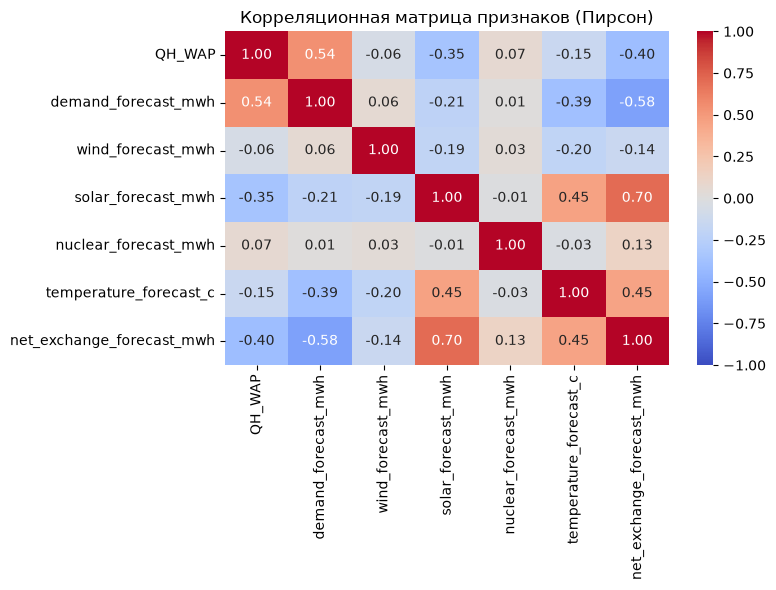

In [193]:
data = df.drop(labels='timestamp',axis=1)
corr = df.corr(numeric_only=True)
plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title("Корреляционная матрица признаков (Пирсон)")
plt.tight_layout()
plt.show()

Text(0.5, 1.0, 'Корреляционная матрица (Спирмана)')

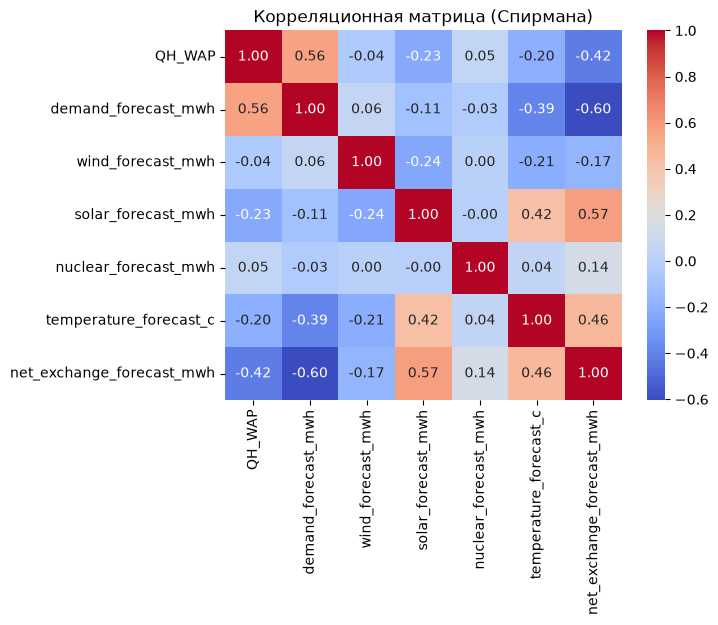

In [194]:
corr = df.corr(method='spearman', numeric_only=True)
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm')
plt.title("Корреляционная матрица (Спирмана)")

| Признаки | Корреляция | Комментарий |
|---|---|---|
| demand и net_exchange | −0.60 | Чем больше потребление тем больше импортируют (отрицательная связб) |
| solar_forecast и net_exchange | 0.57 | Чем больше выроботка солнцем, тем меньше импортируют (положительная связь) |
| nuclear и др | ~0 | АЭС не зависит от других признаков |


>С целевеой переменной лучше всего коллерируют demand...(положительная связб) и net_exchange(отрицательная связь)

Text(0.5, 1.0, 'Корреляционная матрица (Кендалла)')

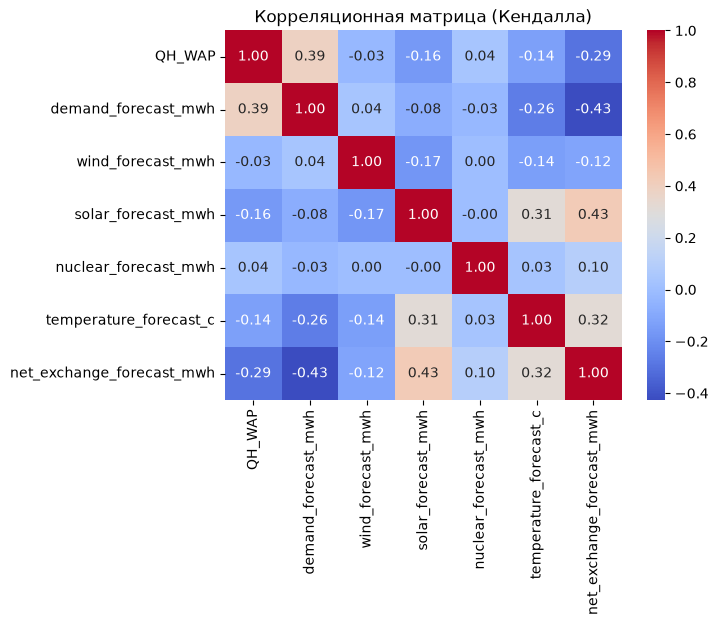

In [195]:
corr = df.corr(method='kendall', numeric_only=True)
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm')
plt.title("Корреляционная матрица (Кендалла)")

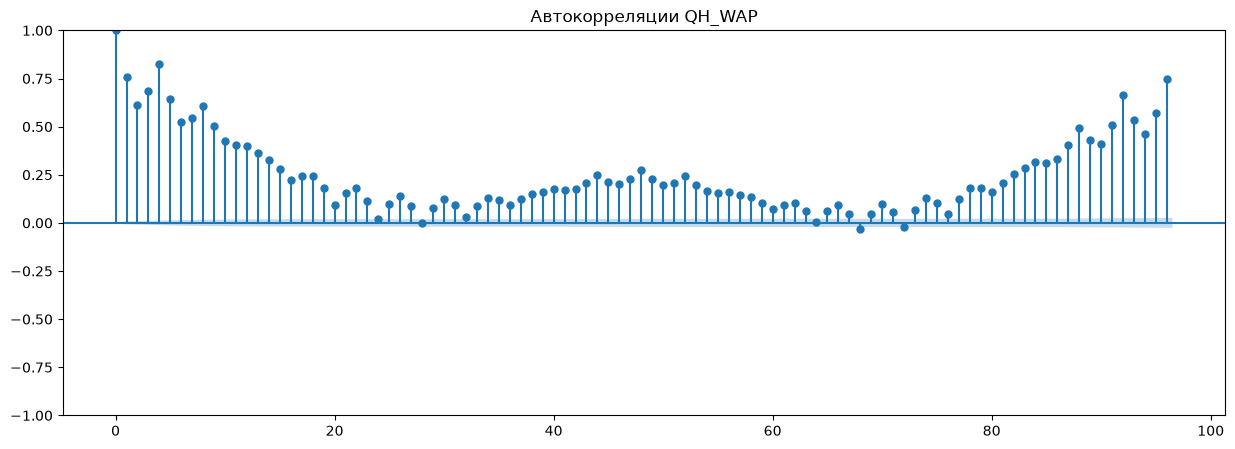

In [200]:
fig, ax = plt.subplots(figsize=(15, 5))

plot_acf(
    df['QH_WAP'].interpolate(),
    lags=96,
    ax=ax,
    fft=True,
)
plt.title('Автокорреляции QH_WAP')
plt.show()




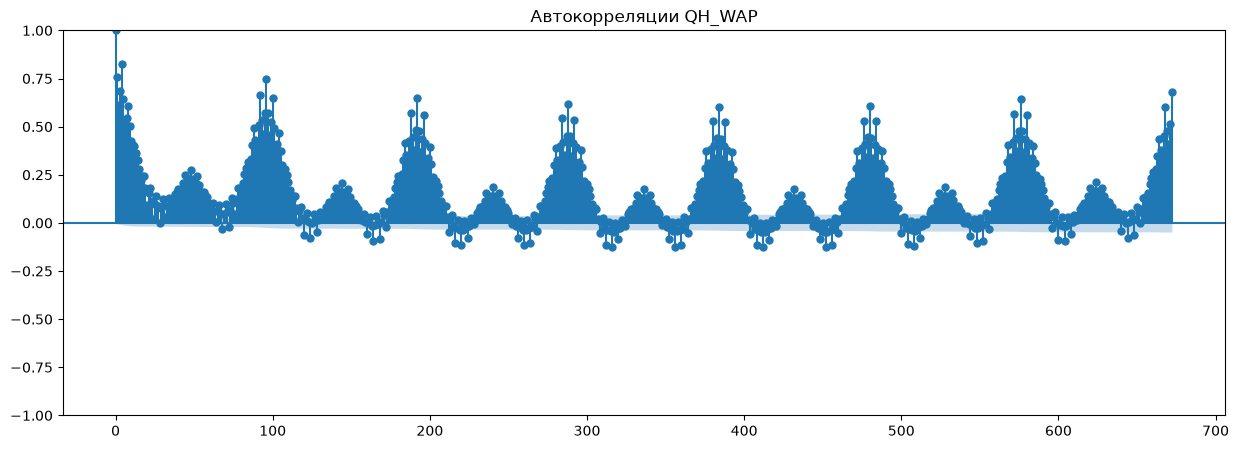

In [199]:
fig, ax = plt.subplots(figsize=(15, 5))

plot_acf(
    df['QH_WAP'],
    lags=96*7,
    ax=ax,
    fft=True,
)
plt.title('Автокорреляции QH_WAP')
plt.show()

Корреляция постепенно убывает с увеличением лага, однако снова увеличиваеться когда приближается к предыдущему дню, тоже самое с недельным

Вывод:

* Присутсвует суточная сезонность
* Присутсвует недельная сезонность


### Выводы



1. Пропуски есть в целевой переменной (96 пропусков) - они были заполнены медианной ценой для этого времени суток. 


2. Присутсвуют аномалии у признаков и целевой переменной:
* demand_forecast_mwh: 47 0.04%

* wind_forecast_mwh: 3719 3.53%

* solar_forecast_mwh: 5510 5.24%

* net_exchange_forecast_mwh: 2404 2.28%

* QT_WAP 5470 5.20% (по rolling z-score 1.4 %) - было принято решение заклипать все что больше 377.66 и все что ниже -29.509499999999992.

Остальные аномалии не обязательно являются выбросами - скачки могут быть у солнечного дня (резко больше солнца). С ветром тоже самое тут не предскажешь. Погодные условия можно сказать не очень предсказуемы.


3. С целевой переменной лучше всего коллерируют 
* demand...(положительная связб)
* net_exchange(отрицательная связь)
Также присутвует связи: demand и net_exchange (Чем больше потребление тем больше импортируют (отрицательная связь)),
solar_forecast и net_exchange (Чем больше выроботка солнцем, тем меньше импортируют (положительная связь)).

А вот признак nuclear вообще не коллерируют с остальными признаками и таргетом.

4. Присутсвует сезонность у признаков. Такие признаки зависят от времени суток, квартала и дня недели

5. С помощью автокорреляции получилось понять что у таргета есть суточная сезонность и недельная сезонность. 

